# 03｜EEG 参考设置、数据质控与 ICA

本项目演示平均参考、简单通道质量指标、ICA 拟合与人工检查。坏道阈值仅作教学示例；ICA 成分必须结合地形图、时间序列及眼电/肌电信息判断。默认不自动删除任何成分。


In [1]:
import mne
import numpy as np
import pandas as pd
import os
import json

# 读取滤波后的数据
raw = mne.io.read_raw_fif("results/EEG_filtered_raw.fif", preload=True, verbose=False)

# 设置平均参考（Average Reference）
raw_ref = raw.copy().set_eeg_reference("average", projection=False, verbose=False)

print("平均参考设置完成")
print("通道数：", len(raw_ref.ch_names))

平均参考设置完成
通道数： 64


In [2]:
# 查看不同类型的通道数量
print("通道类型统计：")
print(raw_ref.get_channel_types(picks=None))

# 统计 EEG 通道数量
eeg_channels = mne.pick_types(
    raw_ref.info,
    eeg=True,
    eog=False,
    exclude=[]
)

print("\nEEG 通道数量：", len(eeg_channels))

通道类型统计：
['eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg']

EEG 通道数量： 64


In [3]:
# 创建 ICA 模型
ica = mne.preprocessing.ICA(
    n_components=20,
    method="fastica",
    random_state=42,
    max_iter=1000
)

# 使用平均参考后的 EEG 数据拟合 ICA
ica.fit(raw_ref, verbose=True)

print("ICA 拟合完成")
print("独立成分数量：", ica.n_components_)

Fitting ICA to data using 64 channels (please be patient, this may take a while)
Selecting by number: 20 components
Fitting ICA took 1.7s.
ICA 拟合完成
独立成分数量： 20


In [4]:
# 复制数据，清理通道名称
raw_montage = raw_ref.copy()

rename_dict = {
    ch: ch.rstrip(".")
    for ch in raw_montage.ch_names
}
raw_montage.rename_channels(rename_dict)

# 创建标准电极布局
montage = mne.channels.make_standard_montage(
    "standard_1005"
)

# 根据标准模板自动匹配通道名称
standard_name_map = {
    name.lower(): name
    for name in montage.ch_names
}

rename_dict = {}
unmatched = []

for ch in raw_montage.ch_names:
    standard_name = standard_name_map.get(ch.lower())

    if standard_name is not None:
        rename_dict[ch] = standard_name
    else:
        unmatched.append(ch)

if unmatched:
    raise ValueError(f"未匹配通道：{unmatched}")

raw_montage.rename_channels(rename_dict)

# 设置标准电极位置
raw_montage.set_montage(
    montage,
    on_missing="raise",
    verbose=False
)

print("Montage 设置成功")
print("电极位置数量：", len(raw_montage.get_montage().ch_names))

Montage 设置成功
电极位置数量： 64


In [5]:
print("raw_montage 电极位置：",
      len(raw_montage.info["dig"] or []))

print("ICA 拟合时保存的电极位置：",
      len(ica.info["dig"] or []))

print("ICA 通道数量：",
      len(ica.ch_names))

raw_montage 电极位置： 67
ICA 拟合时保存的电极位置： 0
ICA 通道数量： 64


In [6]:
# 重新创建 ICA 模型
ica = mne.preprocessing.ICA(
    n_components=20,
    method="fastica",
    random_state=42,
    max_iter=1000
)

# 使用已经设置好 Montage 的数据重新拟合
ica.fit(raw_montage, verbose=True)

print("ICA 重新拟合完成")
print("独立成分数量：", ica.n_components_)
print("ICA 电极位置数量：", len(ica.info["dig"] or []))

Fitting ICA to data using 64 channels (please be patient, this may take a while)
Selecting by number: 20 components
Fitting ICA took 0.6s.
ICA 重新拟合完成
独立成分数量： 20
ICA 电极位置数量： 67


In [7]:
import os
import json
import mne

# 检查当前 ICA 模型
print("===== 当前 ICA 模型 =====")

print("成分数量：", ica.n_components_)
print("拟合通道数量：", len(ica.ch_names))
print("算法：", ica.method)
print("排除成分：", ica.exclude)

# 创建保存目录
os.makedirs("results/ICA_model", exist_ok=True)

# 保存 ICA 模型
ica.save(
    "results/ICA_model/EEG_ICA_model.fif",
    overwrite=True
)

# 保存模型参数
model_info = {
    "method": ica.method,
    "n_components": int(ica.n_components_),
    "channels": ica.ch_names,
    "excluded_components": list(ica.exclude),
    "random_state": 42,
    "max_iter": 1000
}

with open(
    "results/ICA_model/ICA_parameters.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(model_info, f, ensure_ascii=False, indent=4)

print("\nICA 模型保存成功")

===== 当前 ICA 模型 =====
成分数量： 20
拟合通道数量： 64
算法： fastica
排除成分： []
Overwriting existing file.
Writing ICA solution to C:\Users\Administrator\results\ICA_model\EEG_ICA_model.fif...
Overwriting existing file.

ICA 模型保存成功


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\1809622234.py:17: RuntimeWarning: This filename (results/ICA_model/EEG_ICA_model.fif) does not conform to MNE naming conventions. All ICA files should end with -ica.fif, -ica.fif.gz, _ica.fif or _ica.fif.gz
  ica.save(


In [8]:
# 从硬盘重新读取 ICA 模型
ica_check = mne.preprocessing.read_ica(
    "results/ICA_model/EEG_ICA_model.fif"
)

print("===== 模型复核 =====")
print("当前模型成分数：", ica_check.n_components_)
print("读取模型成分数：", len(ica_check.get_components().T))
print("拟合通道数：", len(ica_check.ch_names))
print("排除成分：", ica_check.exclude)

Reading C:\Users\Administrator\results\ICA_model\EEG_ICA_model.fif ...
Now restoring ICA solution ...
Ready.
===== 模型复核 =====
当前模型成分数： 20
读取模型成分数： 20
拟合通道数： 64
排除成分： []


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\215502767.py:2: RuntimeWarning: This filename (results/ICA_model/EEG_ICA_model.fif) does not conform to MNE naming conventions. All ICA files should end with -ica.fif, -ica.fif.gz, _ica.fif or _ica.fif.gz
  ica_check = mne.preprocessing.read_ica(


In [9]:
import numpy as np

# 获取当前用于 ICA 的数据，单位是伏特（V）
data = raw_montage.get_data()

# 检查 NaN 和 Inf
nan_count = np.isnan(data).sum()
inf_count = np.isinf(data).sum()

# 转换为微伏（µV），方便理解 EEG 振幅
data_uv = data * 1e6

# 计算每个通道的峰峰值
peak_to_peak = np.ptp(data_uv, axis=1)

print("===== EEG 数据质量检查 =====")
print("数据形状：", data.shape)
print("NaN 数量：", nan_count)
print("Inf 数量：", inf_count)
print("通道数量：", len(raw_montage.ch_names))
print("最大通道峰峰值：", round(np.max(peak_to_peak), 2), "µV")
print("最小通道峰峰值：", round(np.min(peak_to_peak), 2), "µV")
print("平均峰峰值：", round(np.mean(peak_to_peak), 2), "µV")

===== EEG 数据质量检查 =====
数据形状： (64, 20000)
NaN 数量： 0
Inf 数量： 0
通道数量： 64
最大通道峰峰值： 729.96 µV
最小通道峰峰值： 144.99 µV
平均峰峰值： 264.64 µV


In [10]:
import pandas as pd
import numpy as np

# 计算每个通道的峰峰值、标准差和最大绝对振幅
channel_report = pd.DataFrame({
    "通道": raw_montage.ch_names,
    "峰峰值(µV)": np.ptp(data_uv, axis=1),
    "标准差(µV)": np.std(data_uv, axis=1),
    "最大绝对振幅(µV)": np.max(np.abs(data_uv), axis=1)
})

# 按峰峰值从大到小排序
channel_report = channel_report.sort_values(
    by="峰峰值(µV)", ascending=False
)

print("===== 振幅最大的10个通道 =====")
display(channel_report.head(10).round(2))

===== 振幅最大的10个通道 =====


,通道,峰峰值(µV),标准差(µV),最大绝对振幅(µV)
21,Fp1,729.96,52.14,441.55
24,AF7,651.92,45.20,414.09
23,Fp2,625.49,47.28,364.39
25,AF3,623.84,43.13,394.92
22,Fpz,570.18,43.93,348.72
28,AF8,506.78,41.87,291.98
29,F7,397.39,27.40,221.03
30,F5,370.25,29.54,210.40
60,O1,333.46,30.77,181.75
62,O2,331.33,35.18,197.81


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\241789121.py:35: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\241789121.py:35: UserWarning: Glyph 38388 (\N{CJK UNIFIED IDEOGRAPH-95F4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\241789121.py:35: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\241789121.py:35: UserWarning: Glyph 31186 (\N{CJK UNIFIED IDEOGRAPH-79D2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\241789121.py:35: UserWarning: Glyph 65289 (\N{FULLWIDTH RIGHT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\2

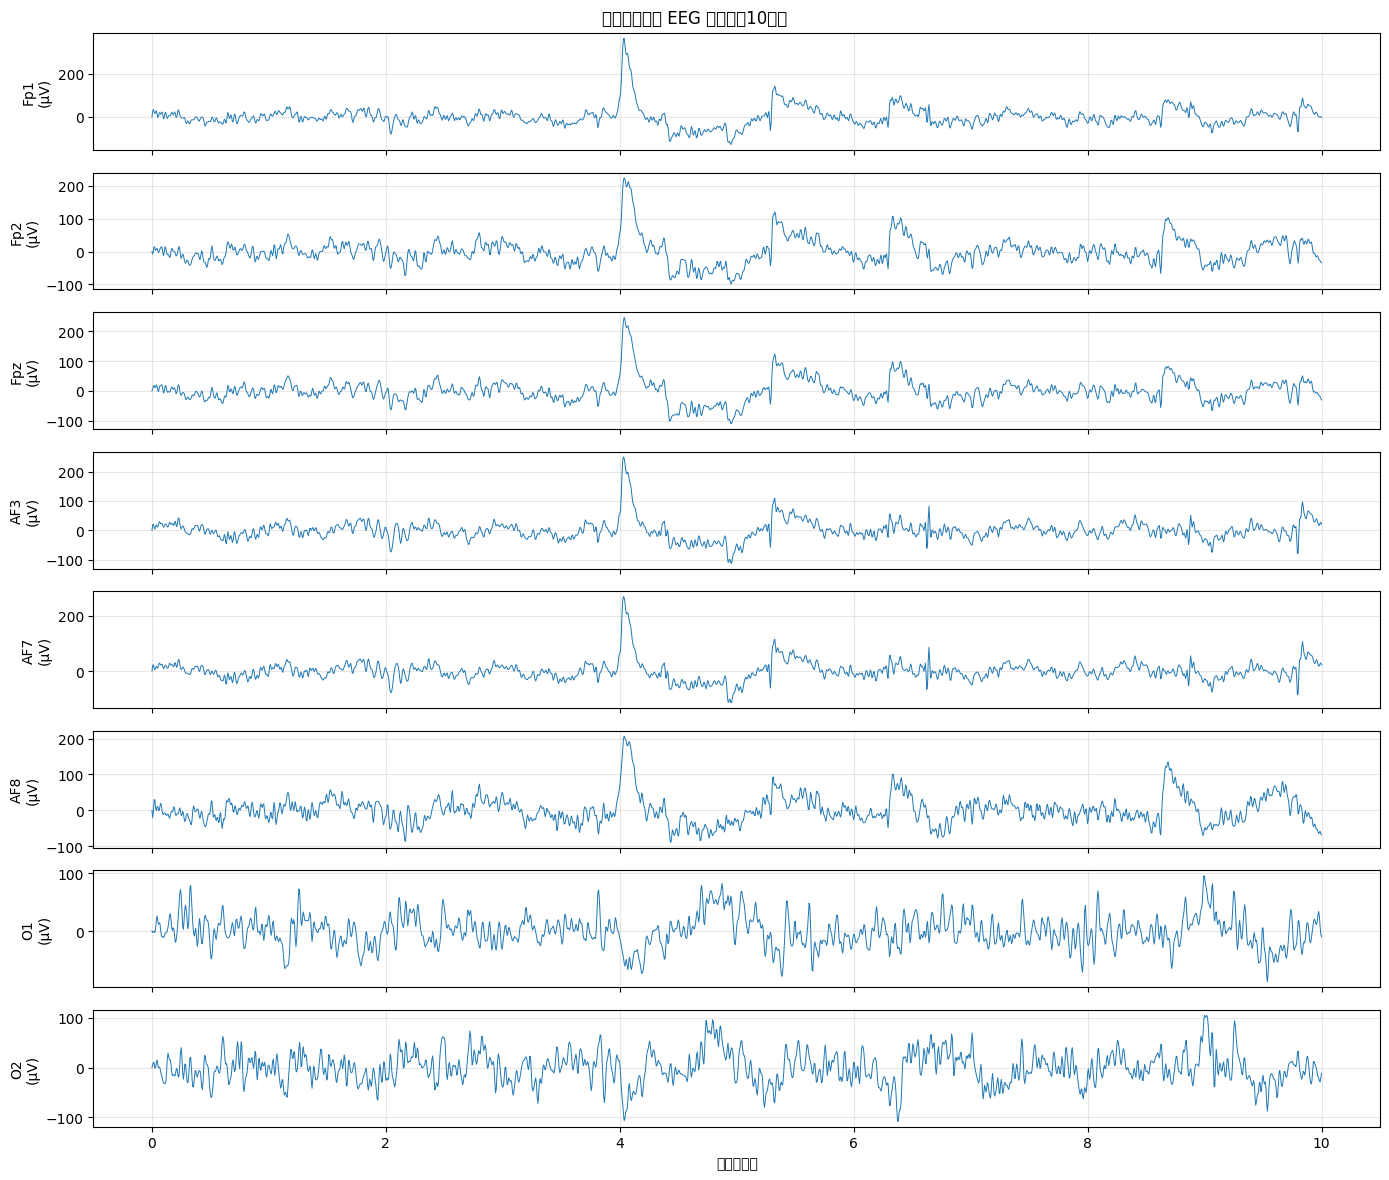

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# 选择需要观察的通道
channels_to_plot = [
    "Fp1", "Fp2", "Fpz",
    "AF3", "AF7", "AF8",
    "O1", "O2"
]

# 截取前10秒
raw_segment = raw_montage.copy().crop(tmin=0, tmax=10)

# 获取信号，转换成微伏
plot_data = raw_segment.get_data(
    picks=channels_to_plot
) * 1e6

times = raw_segment.times

# 绘制波形
fig, axes = plt.subplots(
    len(channels_to_plot), 1,
    figsize=(14, 12),
    sharex=True
)

for i, ax in enumerate(axes):
    ax.plot(times, plot_data[i], linewidth=0.7)
    ax.set_ylabel(channels_to_plot[i] + "\n(µV)")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("时间（秒）")
fig.suptitle("额前区与枕区 EEG 波形（前10秒）")
plt.tight_layout()
plt.show()

C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\322776464.py:28: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\322776464.py:28: UserWarning: Glyph 38388 (\N{CJK UNIFIED IDEOGRAPH-95F4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\322776464.py:28: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\322776464.py:28: UserWarning: Glyph 31186 (\N{CJK UNIFIED IDEOGRAPH-79D2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\322776464.py:28: UserWarning: Glyph 65289 (\N{FULLWIDTH RIGHT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_11784\3

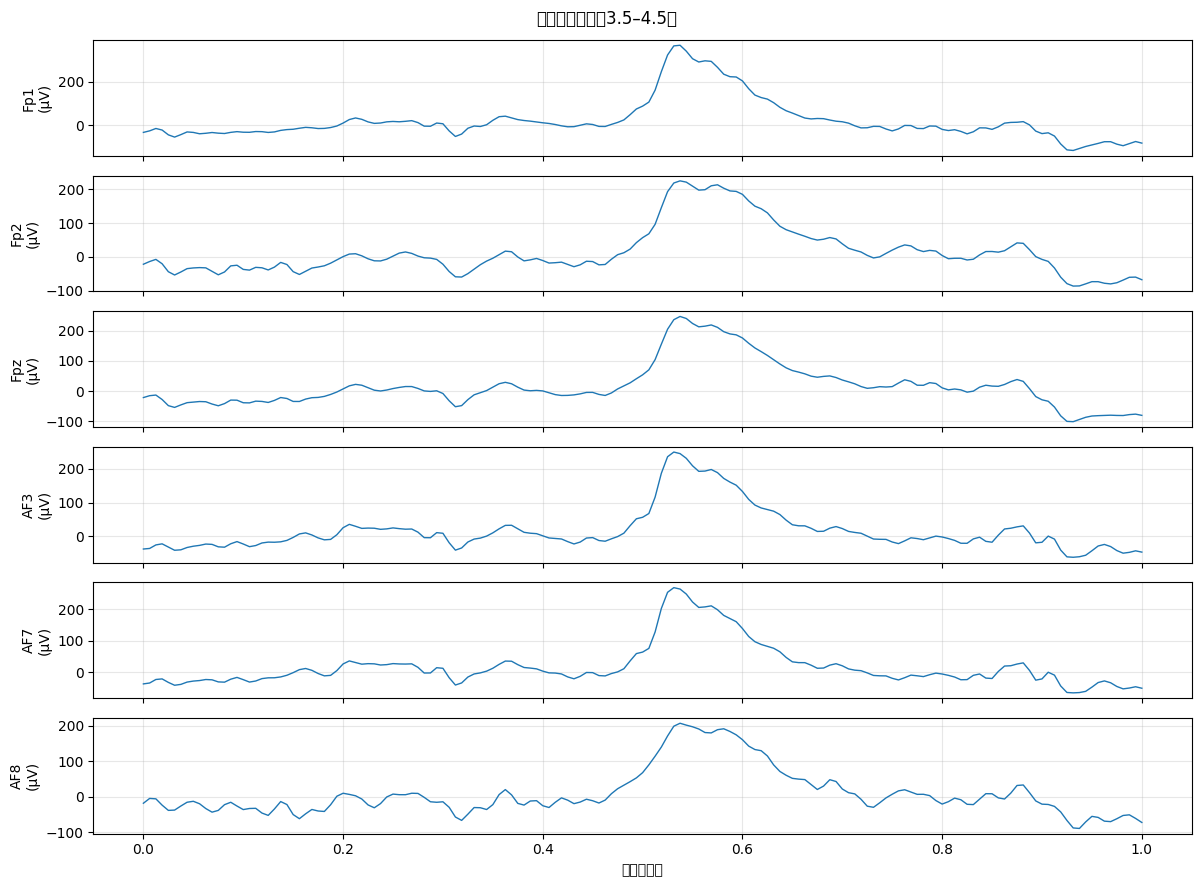

In [12]:
import matplotlib.pyplot as plt

channels = ["Fp1", "Fp2", "Fpz", "AF3", "AF7", "AF8"]

# 截取3.5到4.5秒
segment = raw_montage.copy().crop(
    tmin=3.5,
    tmax=4.5
)

data_zoom = segment.get_data(
    picks=channels
) * 1e6

fig, axes = plt.subplots(
    len(channels), 1,
    figsize=(12, 9),
    sharex=True
)

for i, ax in enumerate(axes):
    ax.plot(segment.times, data_zoom[i], linewidth=1)
    ax.set_ylabel(channels[i] + "\n(µV)")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("时间（秒）")
fig.suptitle("疑似眨眼事件：3.5–4.5秒")
plt.tight_layout()
plt.show()

Creating RawArray with float64 data, n_channels=20, n_times=20000
    Range : 0 ... 19999 =      0.000 ...   124.994 secs
Ready.
Using matplotlib as 2D backend.


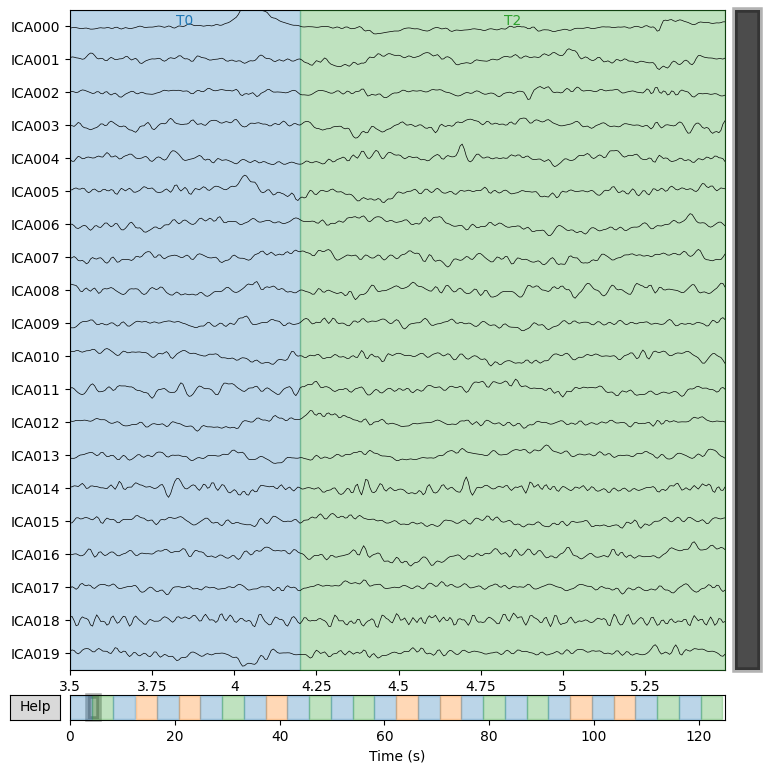

In [13]:
import matplotlib.pyplot as plt

# 直接绘制 ICA 成分
# start 和 stop 指定显示的时间范围（秒）
fig = ica.plot_sources(
    raw_montage,
    start=3.5,
    stop=5.5,
    show=False
)

plt.show()

In [14]:
import numpy as np
import pandas as pd

# 获取全部 ICA 成分数据
sources = ica.get_sources(raw_montage)
source_data = sources.get_data()
times = sources.times

# 事件区间：疑似眨眼
event_mask = (times >= 4.4) & (times <= 4.9)

# 事件前后的基线区间
baseline_mask = (
    ((times >= 3.5) & (times <= 4.2)) |
    ((times >= 5.1) & (times <= 5.5))
)

results = []

for i in range(source_data.shape[0]):
    component = source_data[i]

    baseline = component[baseline_mask]
    event = component[event_mask]

    baseline_std = np.std(baseline)

    event_peak = np.max(
        np.abs(event - np.median(baseline))
    )

    score = event_peak / (baseline_std + 1e-15)

    results.append({
        "ICA成分": f"ICA{i:03d}",
        "事件峰值": event_peak,
        "基线标准差": baseline_std,
        "事件活动评分": score
    })

result_df = pd.DataFrame(results)

result_df = result_df.sort_values(
    "事件活动评分",
    ascending=False
)

display(result_df.head(10).round(3))

,ICA成分,事件峰值,基线标准差,事件活动评分
4,ICA004,4.397,0.951,4.625
2,ICA002,2.260,0.575,3.931
16,ICA016,3.944,1.009,3.910
14,ICA014,3.281,0.888,3.694
9,ICA009,2.293,0.637,3.600
7,ICA007,3.226,0.898,3.592
5,ICA005,3.904,1.100,3.550
11,ICA011,3.414,0.965,3.537
17,ICA017,2.304,0.662,3.480
10,ICA010,3.431,1.107,3.100


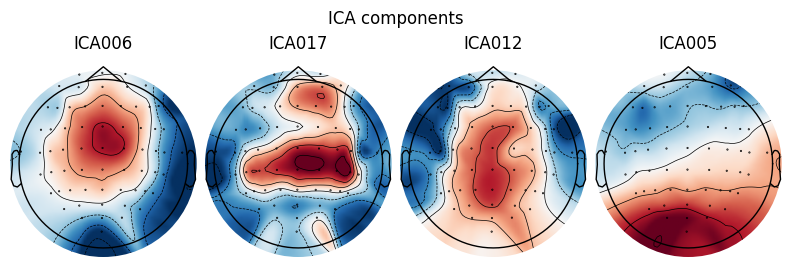

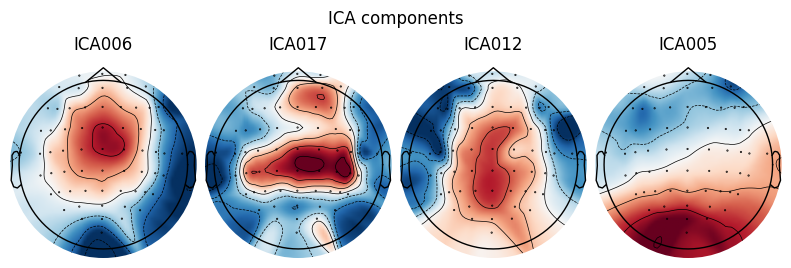

In [15]:
# 查看前4个候选 ICA 成分的头皮地形图
ica.plot_components(
    picks=[6, 17, 12, 5],
    show=True
)

In [16]:
import os
import matplotlib.pyplot as plt

# 创建保存文件夹
save_dir = "results/ICA_candidates"
os.makedirs(save_dir, exist_ok=True)

# 需要重点检查的5个成分
candidate_ids = [0, 7, 8, 14, 18]

# 生成5张独立诊断图
figs = ica.plot_properties(
    raw_montage,
    picks=candidate_ids,
    show=False
)

# 分别保存
for component_id, fig in zip(candidate_ids, figs):

    file_path = os.path.join(
        save_dir,
        f"ICA{component_id:03d}_diagnostic.png"
    )

    fig.savefig(
        file_path,
        dpi=250,
        bbox_inches="tight"
    )

    plt.close(fig)

    print("已保存：", file_path)

print("\n5张 ICA 诊断图全部保存完成！")

    Using multitaper spectrum estimation with 7 DPSS windows
Not setting metadata
62 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
62 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
62 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
62 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
62 matching events found
No baseline correction applied
0 projection items activated
已保存： results/ICA_candidates\ICA000_diagnostic.png
已保存： results/ICA_candidates\ICA007_diagnostic.png
已保存： results/ICA_candidates\ICA008_diagnostic.png
已保存： results/ICA_candidates\ICA014_diagnostic.png
已保存： results/ICA_candidates\ICA018_diagnostic.png

5张 ICA 诊断图全部保存完成！


    Using multitaper spectrum estimation with 7 DPSS windows
Not setting metadata
62 matching events found
No baseline correction applied
0 projection items activated


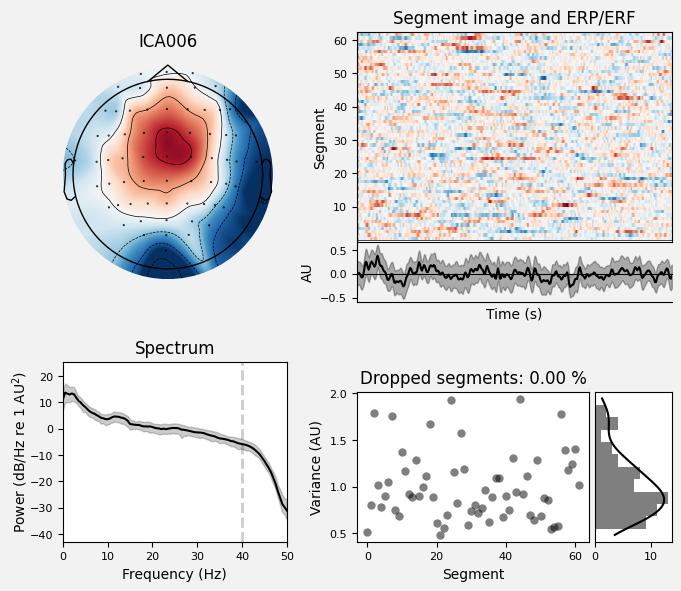

[<Figure size 700x600 with 6 Axes>]

In [17]:
ica.plot_properties(
    raw_montage,
    picks=[6],
    show=True
)

D:\Anaconda\envs\eeg\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 27963 (\N{CJK UNIFIED IDEOGRAPH-6D3B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\envs\eeg\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21160 (\N{CJK UNIFIED IDEOGRAPH-52A8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\envs\eeg\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\envs\eeg\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65289 (\N{FULLWIDTH RIGHT PARENTHESIS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda\envs\eeg\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 22312 (\N{CJK UNIFIED IDEOGRAPH-5728}) missing from font(s) DejaVu Sans.
  fig.canvas.pri

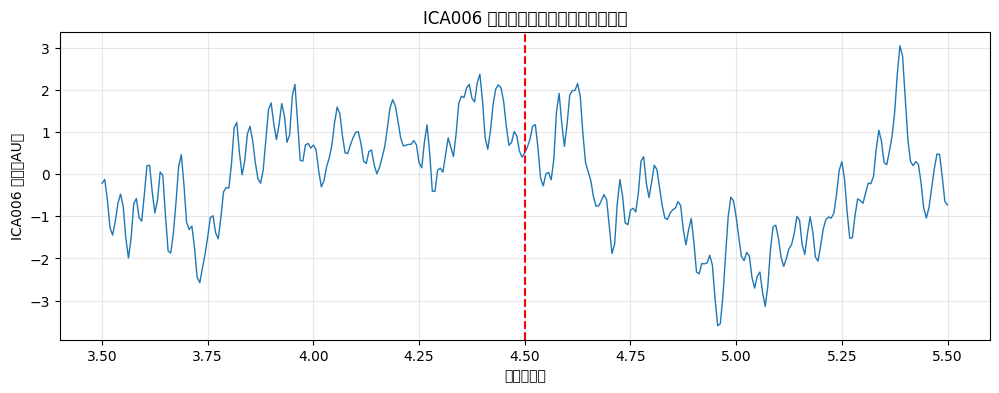

In [18]:
import matplotlib.pyplot as plt
import numpy as np

# 获取 ICA 成分数据
sources = ica.get_sources(raw_montage)
ica_data = sources.get_data()
times = sources.times

# 获取 ICA006
component_6 = ica_data[6]

# 截取 3.5～5.5 秒
mask = (times >= 3.5) & (times <= 5.5)

plt.figure(figsize=(12, 4))

plt.plot(
    times[mask],
    component_6[mask],
    linewidth=1
)

plt.axvline(4.5, linestyle="--", color="red")
plt.xlabel("时间（秒）")
plt.ylabel("ICA006 活动（AU）")
plt.title("ICA006 在疑似眨眼事件附近的时间序列")
plt.grid(alpha=0.3)
plt.show()

In [19]:
import numpy as np
import pandas as pd

# 提取额前区通道
frontal_data = raw_montage.get_data(
    picks=["Fp1", "Fp2", "Fpz", "AF3", "AF7", "AF8"]
)

# 计算额前区平均信号
frontal_mean = np.mean(frontal_data, axis=0)

# 获取 ICA006
ica006 = ica.get_sources(raw_montage).get_data()[6]

# 选择疑似眨眼事件区间
mask = (times >= 4.4) & (times <= 4.9)

# 计算相关系数
correlation = np.corrcoef(
    frontal_mean[mask],
    ica006[mask]
)[0, 1]

print("===== ICA006 相关性检查 =====")
print("额前区与 ICA006 相关系数：", round(correlation, 4))
print("相关系数绝对值：", round(abs(correlation), 4))

===== ICA006 相关性检查 =====
额前区与 ICA006 相关系数： -0.236
相关系数绝对值： 0.236


In [20]:
# 获取数据矩阵 (通道数, 时间点)
data = raw_ref.get_data()

# 1. 计算每个通道的标准差
std_per_channel = np.std(data, axis=1)

# 2. 计算每个通道的峰峰值 (最大值 - 最小值)
ptp_per_channel = np.ptp(data, axis=1)

# 3. 简单的坏道检测规则（教学示例）
# 平直通道：标准差极低
flat_threshold = 1e-8
is_flat = std_per_channel < flat_threshold

# 振幅异常：峰峰值过大 (例如 > 500 微伏，具体阈值视数据而定)
amplitude_threshold = 500e-6  # 500 微伏
is_high_amplitude = ptp_per_channel > amplitude_threshold

# 构建质控 DataFrame
qc_df = pd.DataFrame({
    "Channel": raw_ref.ch_names,
    "Std": std_per_channel,
    "PeakToPeak": ptp_per_channel,
    "IsFlat": is_flat,
    "IsHighAmplitude": is_high_amplitude
})

qc_df.set_index("Channel", inplace=True)

print(qc_df.head())
print("\n平直通道数量：", is_flat.sum())
print("振幅异常通道数量：", is_high_amplitude.sum())

              Std  PeakToPeak  IsFlat  IsHighAmplitude
Channel                                               
Fc5.     0.000019    0.000210   False            False
Fc3.     0.000018    0.000177   False            False
Fc1.     0.000018    0.000183   False            False
Fcz.     0.000021    0.000216   False            False
Fc2.     0.000019    0.000181   False            False

平直通道数量： 0
振幅异常通道数量： 6


In [21]:
import numpy as np
import pandas as pd

data_uv = raw_montage.get_data() * 1e6

quality_report = pd.DataFrame({
    "Channel": raw_montage.ch_names,
    "Std": np.std(data_uv, axis=1),
    "PeakToPeak": np.ptp(data_uv, axis=1),
    "MaxAbsAmplitude": np.max(np.abs(data_uv), axis=1)
})

# 暂时使用峰峰值 > 500 µV 作为高振幅候选筛查阈值
quality_report["IsFlat"] = quality_report["Std"] < 1.0
quality_report["IsHighAmplitude"] = (
    quality_report["PeakToPeak"] > 500
)

print("===== 通道质量报告 =====")
display(
    quality_report.sort_values(
        "PeakToPeak",
        ascending=False
    ).round(2)
)

print("平直通道数量：",
      quality_report["IsFlat"].sum())

print("高振幅候选通道数量：",
      quality_report["IsHighAmplitude"].sum())

===== 通道质量报告 =====


,Channel,Std,PeakToPeak,MaxAbsAmplitude,IsFlat,IsHighAmplitude
21,Fp1,52.14,729.96,441.55,False,True
24,AF7,45.20,651.92,414.09,False,True
23,Fp2,47.28,625.49,364.39,False,True
25,AF3,43.13,623.84,394.92,False,True
22,Fpz,43.93,570.18,348.72,False,True
...,...,...,...,...,...,...
16,CP1,18.11,173.10,96.23,False,False
9,C1,16.52,167.63,88.75,False,False
14,CP5,18.44,166.67,89.98,False,False
7,C5,17.89,158.24,87.97,False,False


平直通道数量： 0
高振幅候选通道数量： 6


In [22]:
# 提取高振幅候选通道
high_amp_channels = quality_report[
    quality_report["IsHighAmplitude"]
].copy()

print("===== 高振幅候选通道详情 =====")

display(
    high_amp_channels.sort_values(
        "PeakToPeak",
        ascending=False
    ).round(2)
)

===== 高振幅候选通道详情 =====


,Channel,Std,PeakToPeak,MaxAbsAmplitude,IsFlat,IsHighAmplitude
21,Fp1,52.14,729.96,441.55,False,True
24,AF7,45.20,651.92,414.09,False,True
23,Fp2,47.28,625.49,364.39,False,True
25,AF3,43.13,623.84,394.92,False,True
22,Fpz,43.93,570.18,348.72,False,True
28,AF8,41.87,506.78,291.98,False,True


In [23]:
import numpy as np
import pandas as pd

# 获取6个候选通道的数据（单位：µV）
channels = high_amp_channels["Channel"].tolist()

segment_data = raw_montage.get_data(
    picks=channels
) * 1e6

sfreq = raw_montage.info["sfreq"]

# 每5秒为一个时间窗口
window_samples = int(5 * sfreq)
n_windows = segment_data.shape[1] // window_samples

rows = []

for ch_idx, ch_name in enumerate(channels):
    for w in range(n_windows):
        start = w * window_samples
        end = start + window_samples

        segment = segment_data[ch_idx, start:end]

        rows.append({
            "Channel": ch_name,
            "时间段": f"{w*5}-{(w+1)*5}s",
            "PeakToPeak": np.ptp(segment)
        })

segment_report = pd.DataFrame(rows)

# 查看每个通道振幅最大的时间段
display(
    segment_report.sort_values(
        "PeakToPeak",
        ascending=False
    ).groupby("Channel").head(3).round(2)
)

,Channel,时间段,PeakToPeak
20,Fp1,100-105s,688.75
13,Fp1,65-70s,666.42
88,AF7,65-70s,628.48
70,Fp2,100-105s,609.59
113,AF3,65-70s,598.31
95,AF7,100-105s,579.34
63,Fp2,65-70s,578.98
120,AF3,100-105s,550.52
45,Fpz,100-105s,548.82
38,Fpz,65-70s,526.77


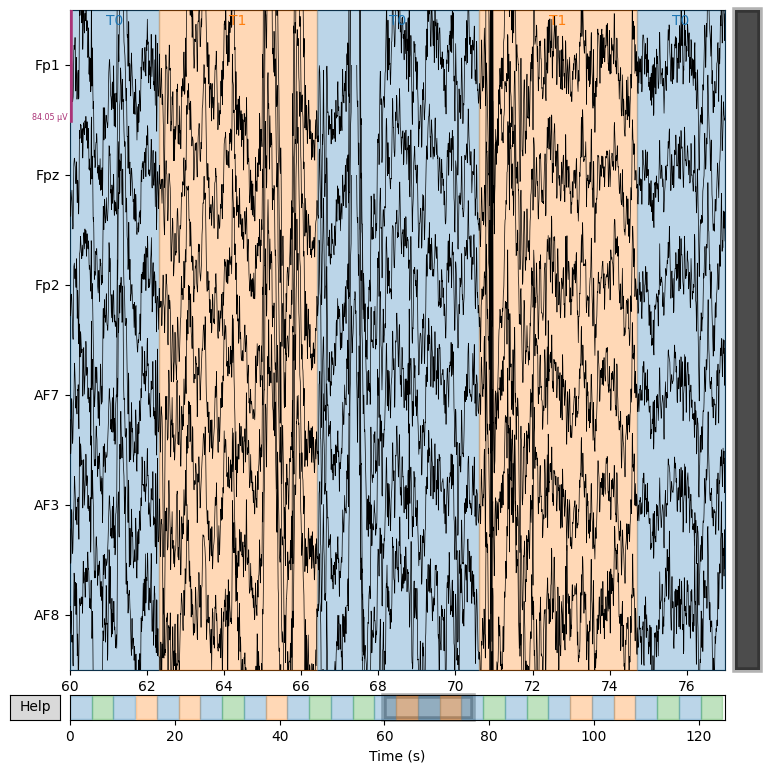

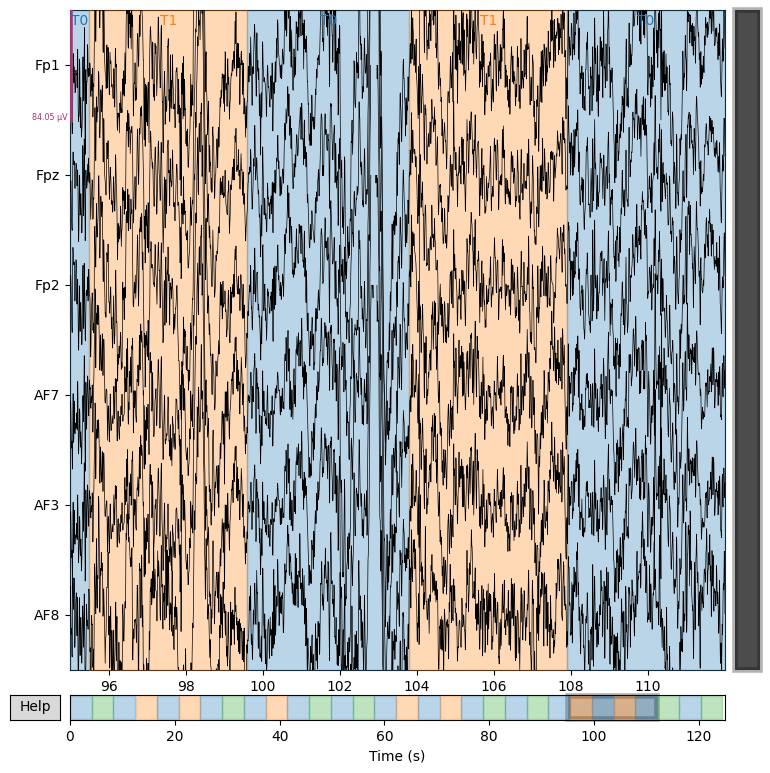

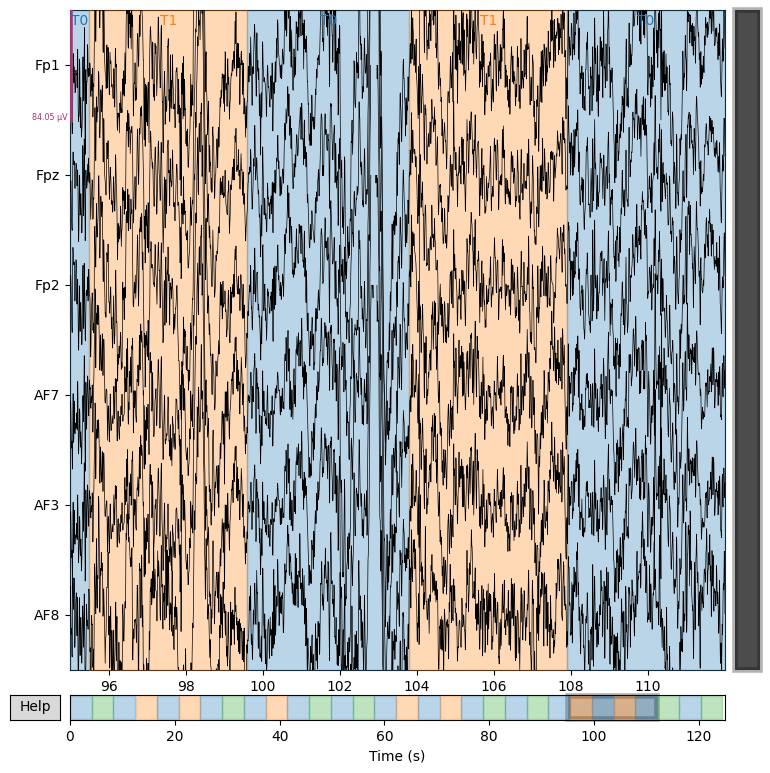

In [24]:
# 选取6个高振幅候选通道
channels = high_amp_channels["Channel"].tolist()

# 观察65-77秒
raw_montage.copy().pick(channels).plot(
    start=60,
    duration=17,
    n_channels=6,
    scalings="auto"
)

# 观察95-112秒
raw_montage.copy().pick(channels).plot(
    start=95,
    duration=17,
    n_channels=6,
    scalings="auto"
)

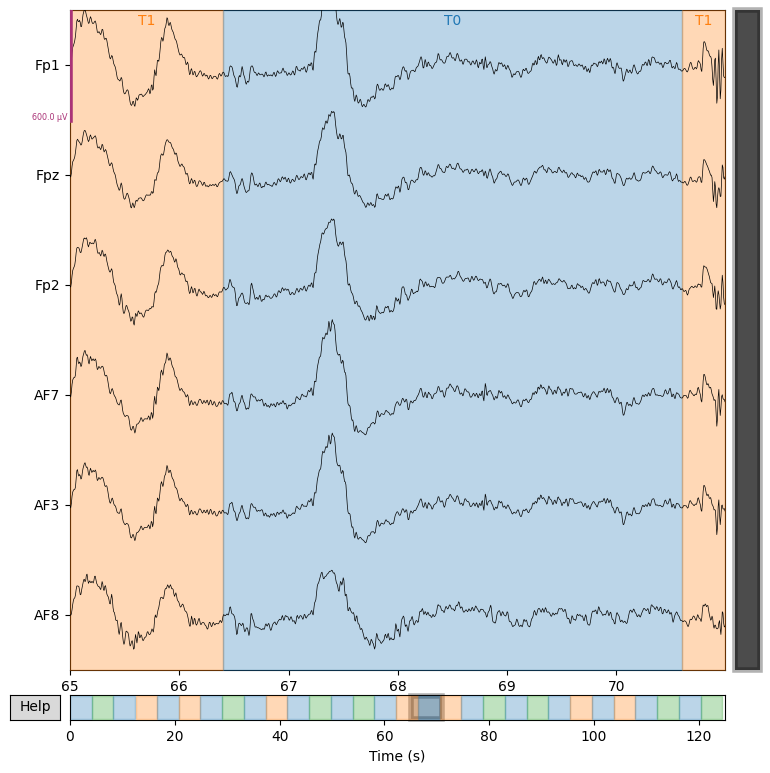

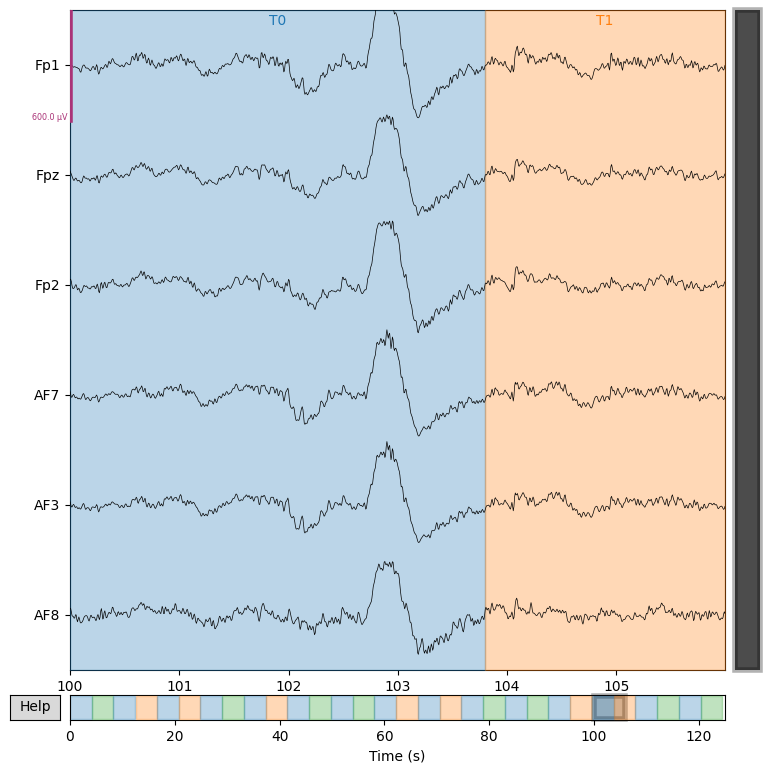

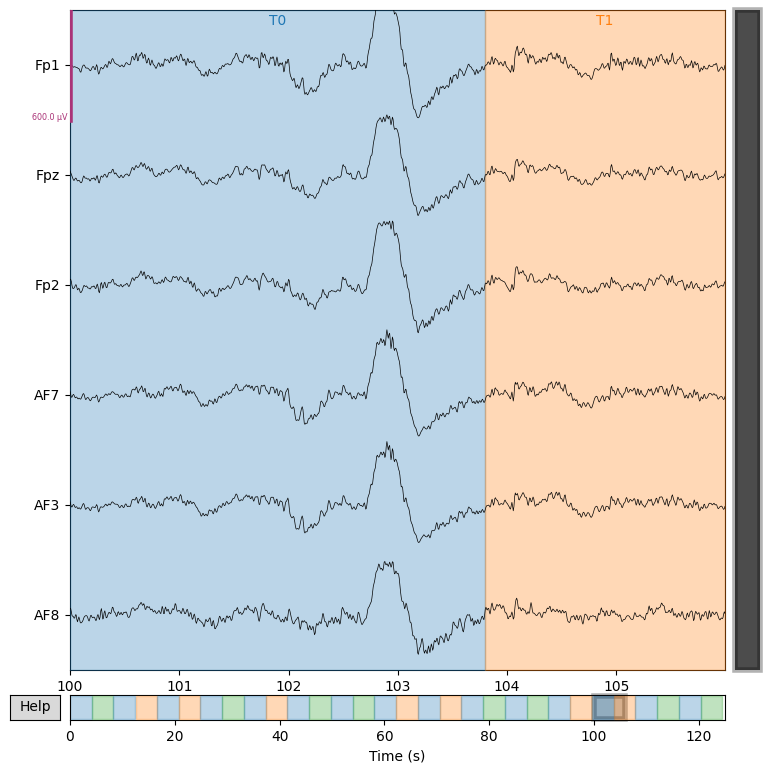

In [25]:
# 放大观察 65-71 秒
raw_montage.copy().pick(channels).plot(
    start=65,
    duration=6,
    n_channels=6,
    scalings={"eeg": 300e-6},
)

# 放大观察 100-106 秒
raw_montage.copy().pick(channels).plot(
    start=100,
    duration=6,
    n_channels=6,
    scalings={"eeg": 300e-6}
)

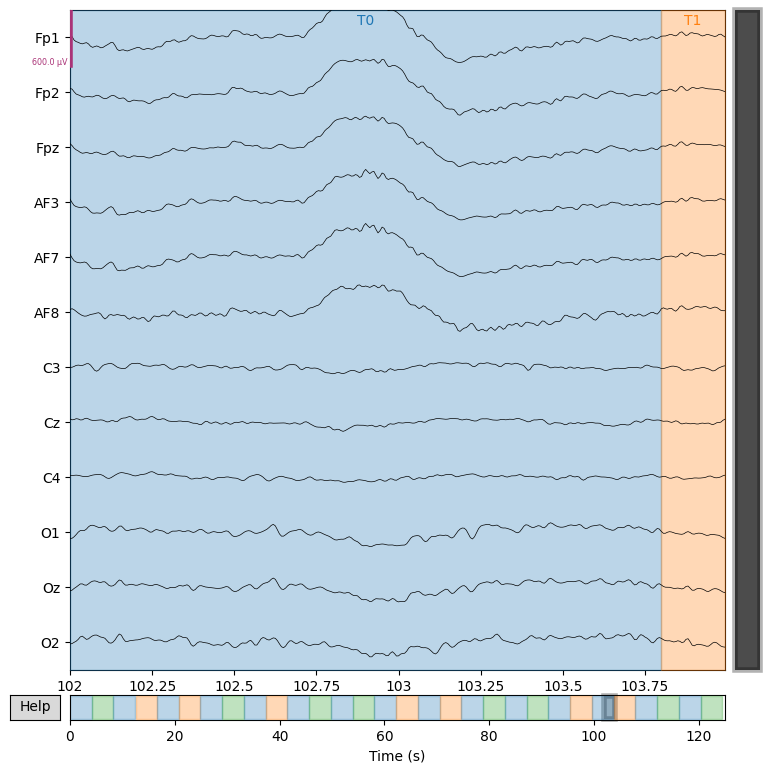

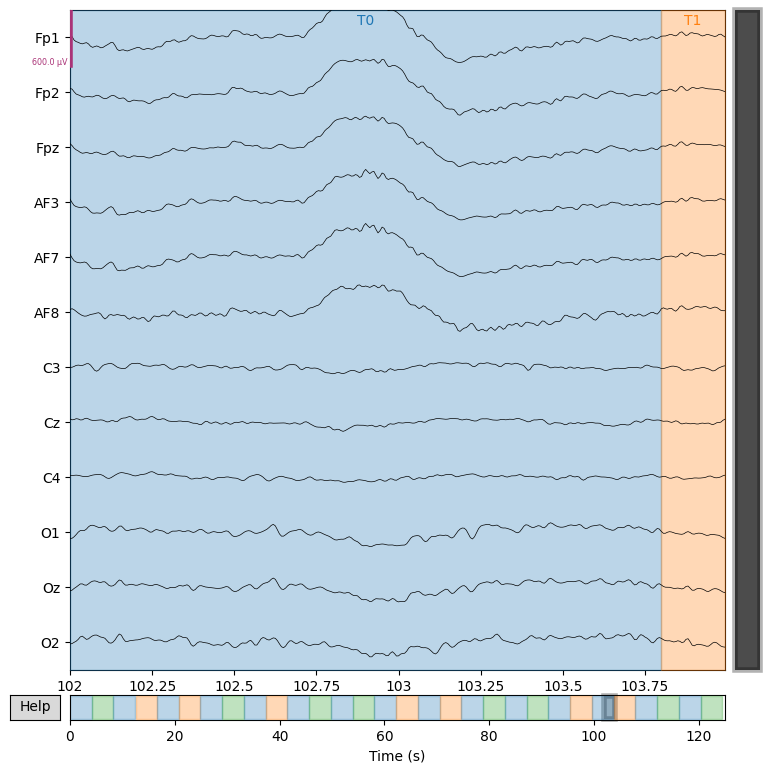

In [26]:
# 选取额前、中央和枕区通道
check_channels = [
    "Fp1", "Fp2", "Fpz",
    "AF3", "AF7", "AF8",
    "C3", "Cz", "C4",
    "O1", "Oz", "O2"
]

# 检查通道是否存在
check_channels = [
    ch for ch in check_channels
    if ch in raw_montage.ch_names
]

# 放大观察102-104秒
raw_montage.copy().pick(check_channels).plot(
    start=102,
    duration=2,
    n_channels=len(check_channels),
    scalings={"eeg": 300e-6}
)

Creating RawArray with float64 data, n_channels=20, n_times=20000
    Range : 0 ... 19999 =      0.000 ...   124.994 secs
Ready.


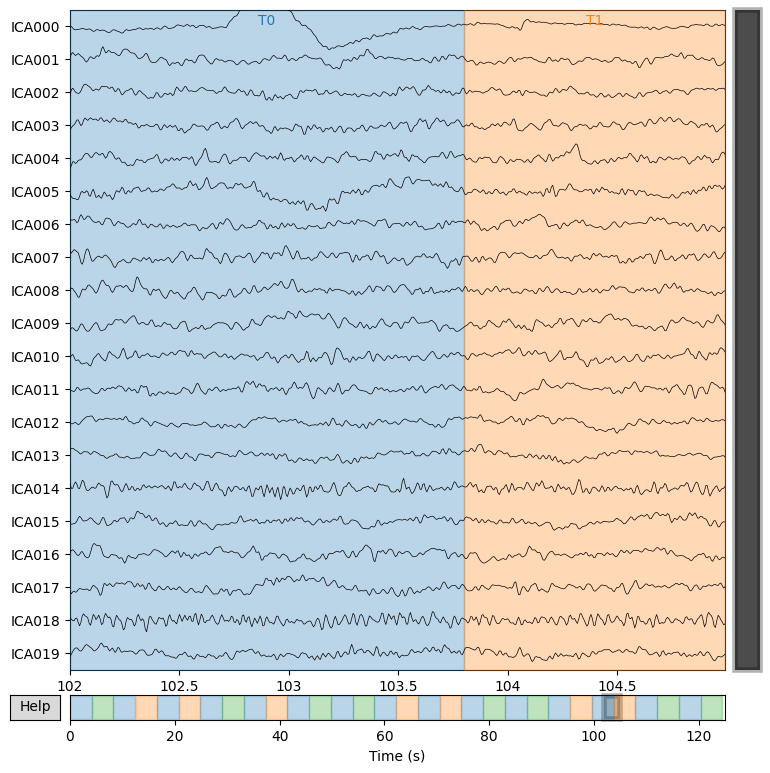

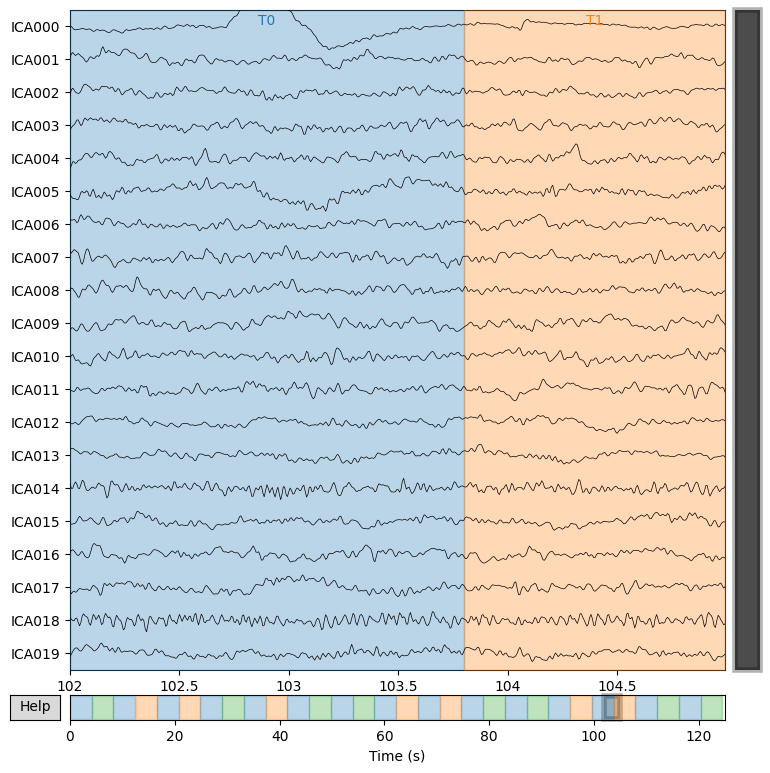

In [27]:
# 查看102-105秒的 ICA 成分活动
ica.plot_sources(
    raw_montage,
    start=102,
    stop=105
)

    Using multitaper spectrum estimation with 7 DPSS windows
Not setting metadata
62 matching events found
No baseline correction applied
0 projection items activated


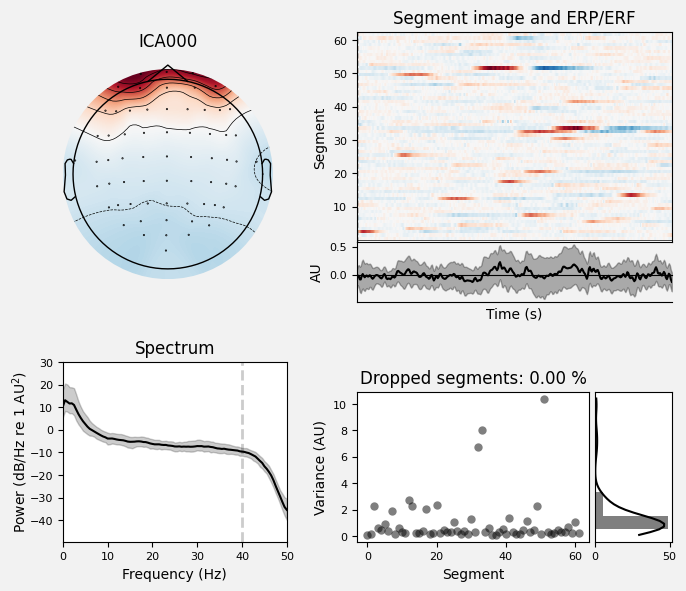

[<Figure size 700x600 with 6 Axes>]

In [28]:
ica.plot_properties(
    raw_montage,
    picks=[0]
)

In [29]:
# 提取 ICA 成分信号
ica_sources = ica.get_sources(raw_montage)

# 获取 ICA000 的数据
component_data = ica_sources.get_data(picks=[0])[0]

sfreq = raw_montage.info["sfreq"]

# 定义事件时间段
event_start = int(102.7 * sfreq)
event_end = int(103.5 * sfreq)

# 计算事件区间的标准差
event_std = np.std(
    component_data[event_start:event_end]
)

# 计算全数据的标准差
global_std = np.std(component_data)

print("ICA000 事件区间标准差：", round(event_std, 4))
print("ICA000 全局标准差：", round(global_std, 4))
print("事件/全局标准差比值：", round(event_std / global_std, 2))

ICA000 事件区间标准差： 5.013
ICA000 全局标准差： 1.0
事件/全局标准差比值： 5.01


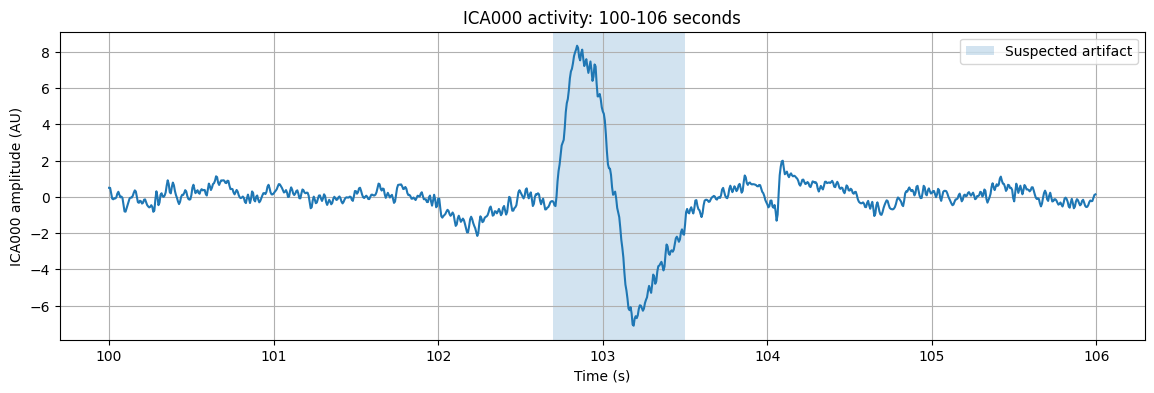

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# 提取 ICA000 信号
ica_sources = ica.get_sources(raw_montage)
component_data = ica_sources.get_data(picks=[0])[0]

sfreq = raw_montage.info["sfreq"]

# 截取100-106秒
start = int(100 * sfreq)
end = int(106 * sfreq)

times = np.arange(start, end) / sfreq
segment = component_data[start:end]

plt.figure(figsize=(14, 4))

plt.plot(times, segment)

# 标记疑似事件区间
plt.axvspan(
    102.7,
    103.5,
    alpha=0.2,
    label="Suspected artifact"
)

plt.xlabel("Time (s)")
plt.ylabel("ICA000 amplitude (AU)")
plt.title("ICA000 activity: 100-106 seconds")
plt.legend()
plt.grid(True)

plt.show()

In [31]:
# 复制 ICA 模型，不修改原模型
ica_test = ica.copy()

# 仅在测试副本中排除 ICA000
ica_test.exclude = [0]

# 应用 ICA 清理
raw_clean_test = ica_test.apply(
    raw_montage.copy()
)

print("测试排除成分：", ica_test.exclude)
print("原始数据时长：", raw_montage.times[-1])
print("清理后数据时长：", raw_clean_test.times[-1])

Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 1 ICA component
    Projecting back using 64 PCA components
测试排除成分： [0]
原始数据时长： 124.99375
清理后数据时长： 124.99375


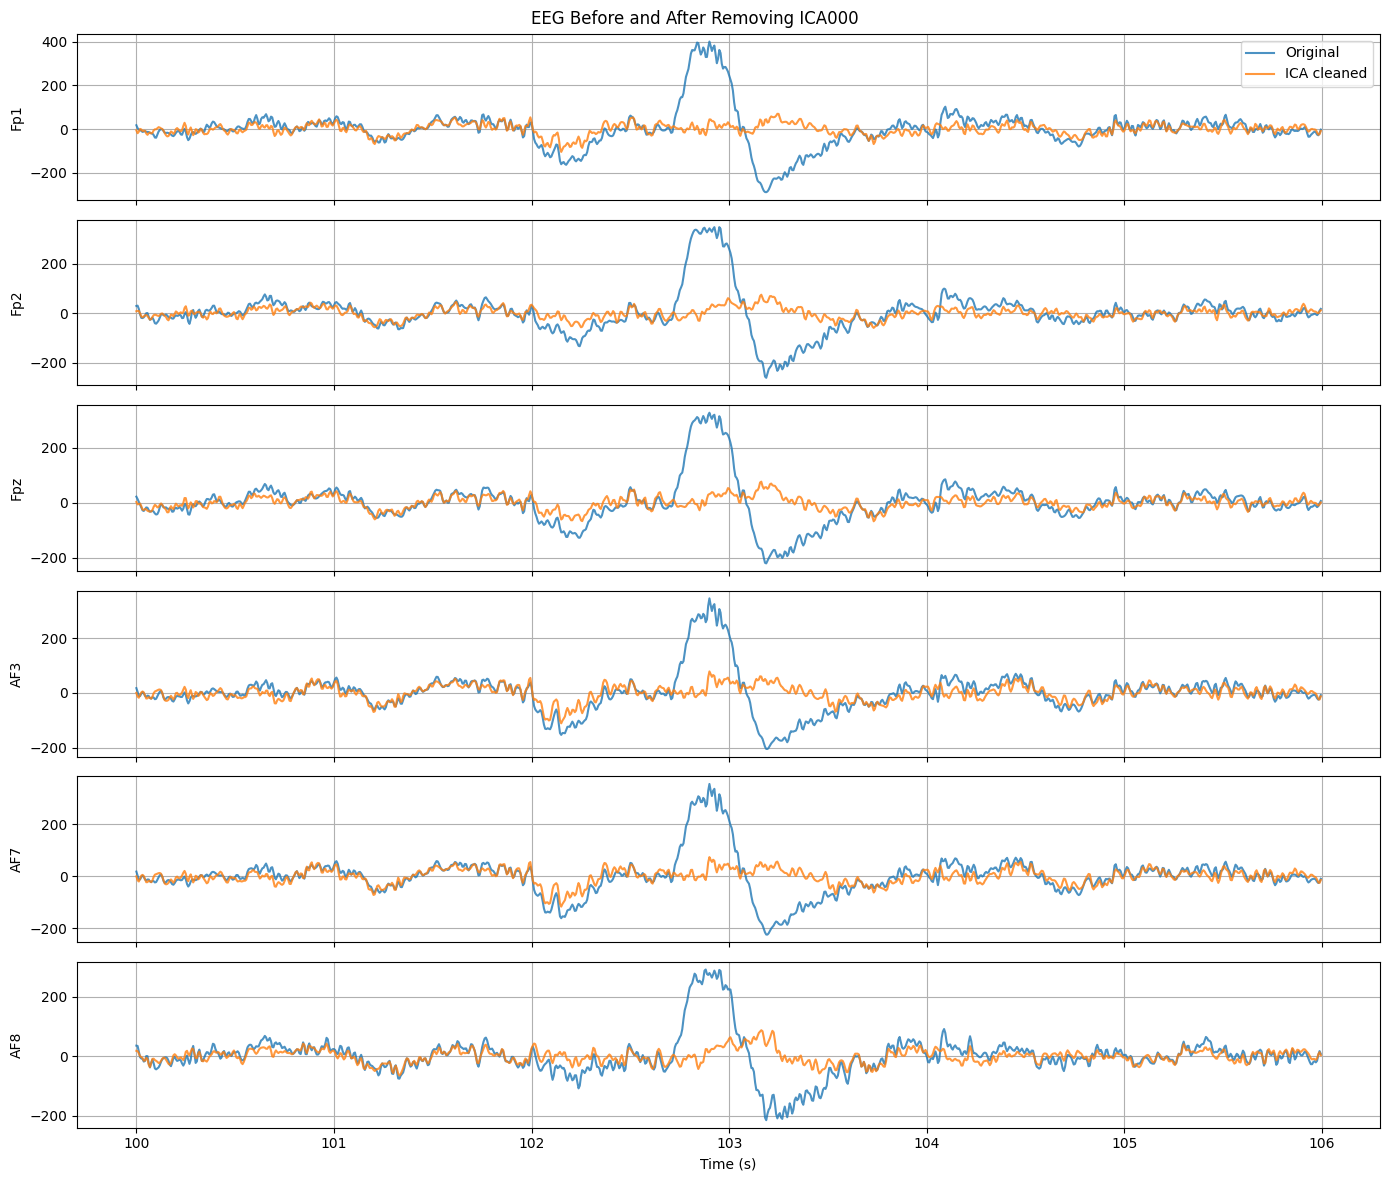

In [32]:
import matplotlib.pyplot as plt
import numpy as np

channels = ["Fp1", "Fp2", "Fpz", "AF3", "AF7", "AF8"]

fig, axes = plt.subplots(
    6, 1,
    figsize=(14, 12),
    sharex=True
)

for i, ch in enumerate(channels):

    # 获取原始数据，转换为 µV
    original = raw_montage.get_data(
        picks=[ch]
    )[0] * 1e6

    # 获取清理后数据，转换为 µV
    cleaned = raw_clean_test.get_data(
        picks=[ch]
    )[0] * 1e6

    # 时间范围：100-106秒
    start = int(100 * raw_montage.info["sfreq"])
    end = int(106 * raw_montage.info["sfreq"])

    times = raw_montage.times[start:end]

    axes[i].plot(
        times, original[start:end],
        label="Original",
        alpha=0.8
    )

    axes[i].plot(
        times, cleaned[start:end],
        label="ICA cleaned",
        alpha=0.8
    )

    axes[i].set_ylabel(ch)
    axes[i].grid(True)

axes[0].legend()
axes[-1].set_xlabel("Time (s)")

plt.suptitle("EEG Before and After Removing ICA000")
plt.tight_layout()
plt.show()

In [ ]:
import mne

raw_final = mne.io.read_raw_fif(
    "results/ICA_model/EEG_ICA_cleaned_raw.fif",
    preload=True,
    verbose=False
)

print("最终数据读取成功")
print("通道数：", len(raw_final.ch_names))
print("采样率：", raw_final.info["sfreq"])
print("数据形状：", raw_final.get_data().shape)
print("数据时长：", raw_final.times[-1])

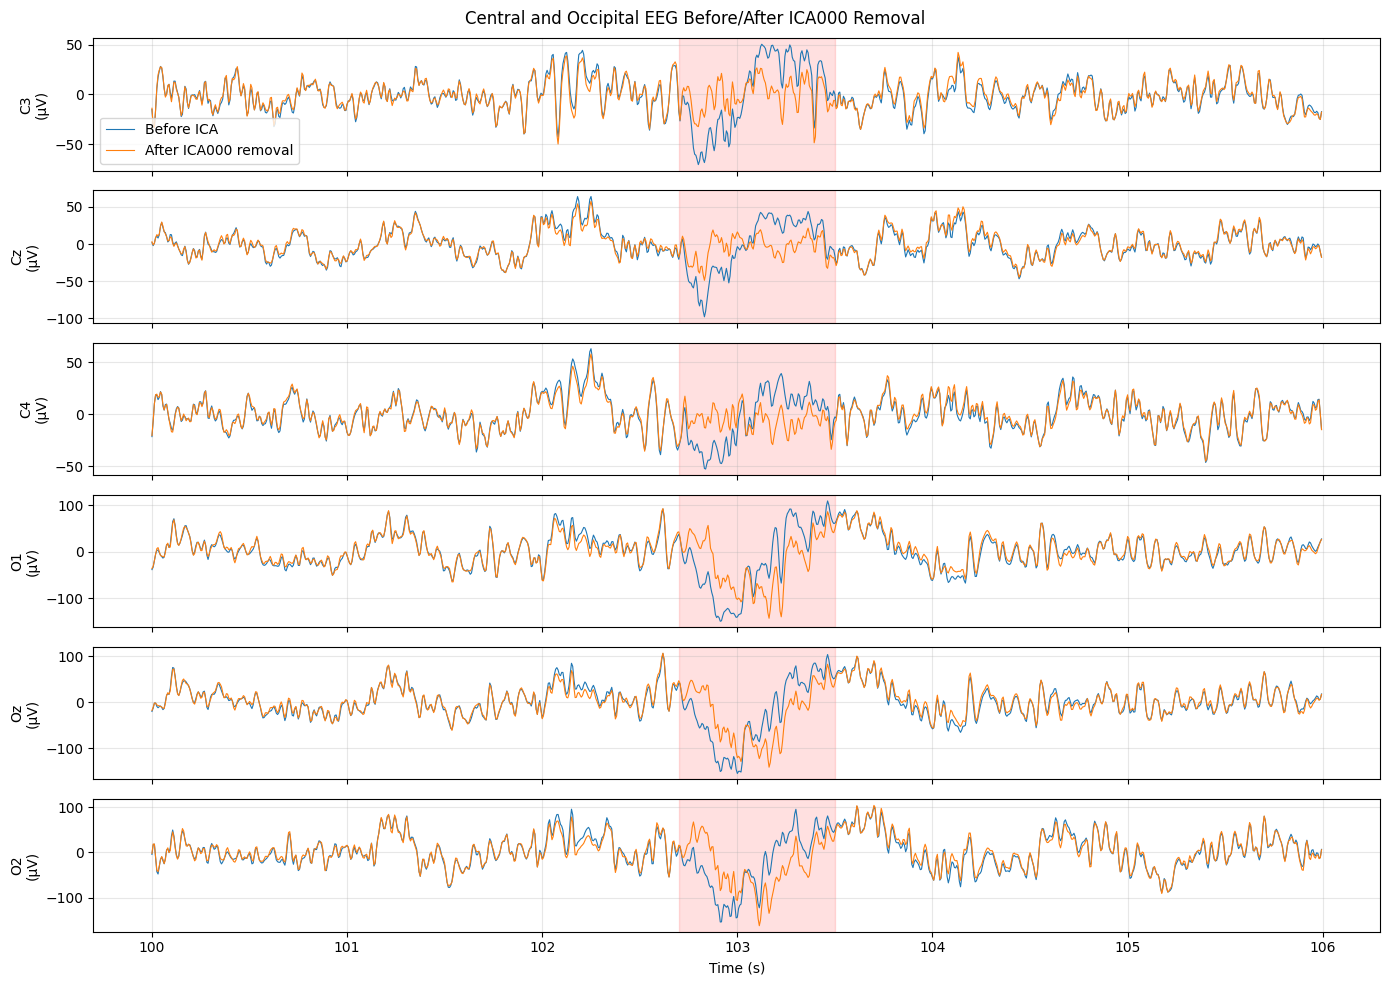

In [44]:
import matplotlib.pyplot as plt
import numpy as np

channels = ["C3", "Cz", "C4", "O1", "Oz", "O2"]

fig, axes = plt.subplots(
    6, 1,
    figsize=(14, 10),
    sharex=True
)

sfreq = raw_montage.info["sfreq"]

# 截取100–106秒
start = int(100 * sfreq)
end = int(106 * sfreq)

times = raw_montage.times[start:end]

for i, ch in enumerate(channels):

    # 清理前
    original = raw_montage.get_data(
        picks=[ch],
        start=start,
        stop=end
    )[0] * 1e6

    # 清理后：使用经过验证的最终数据
    cleaned = raw_final.get_data(
        picks=[ch],
        start=start,
        stop=end
    )[0] * 1e6

    axes[i].plot(
        times, original,
        label="Before ICA",
        linewidth=0.8
    )

    axes[i].plot(
        times, cleaned,
        label="After ICA000 removal",
        linewidth=0.8
    )

    axes[i].axvspan(
        102.7, 103.5,
        color="red",
        alpha=0.12
    )

    axes[i].set_ylabel(f"{ch}\n(µV)")
    axes[i].grid(True, alpha=0.3)

axes[0].legend()
axes[-1].set_xlabel("Time (s)")

plt.suptitle(
    "Central and Occipital EEG Before/After ICA000 Removal"
)

plt.tight_layout()
plt.show()

最终数据读取成功
通道数： 64
采样率： 160.0
数据形状： (64, 20000)
数据时长： 124.99375


In [45]:
import numpy as np
import pandas as pd

regions = {
    "额前区": ["Fp1", "Fp2", "Fpz", "AF3", "AF7", "AF8"],
    "中央区": ["C3", "Cz", "C4"],
    "枕区": ["O1", "Oz", "O2"]
}

sfreq = raw_montage.info["sfreq"]

# 事件区间：102.7–103.5秒
event_start = int(102.7 * sfreq)
event_end = int(103.5 * sfreq)

# 正常参考区间：100–102秒 + 104–106秒
baseline_indices = np.concatenate([
    np.arange(int(100 * sfreq), int(102 * sfreq)),
    np.arange(int(104 * sfreq), int(106 * sfreq))
])

rows = []

for region, ch_names in regions.items():

    # 计算清理前后信号的差值，即被ICA移除的信号
    removed = (
        raw_montage.get_data(picks=ch_names)
        - raw_final.get_data(picks=ch_names)
    ) * 1e6

    event_removed = removed[:, event_start:event_end]
    baseline_removed = removed[:, baseline_indices]

    event_rms = np.sqrt(np.mean(event_removed ** 2))
    baseline_rms = np.sqrt(np.mean(baseline_removed ** 2))

    rows.append({
        "脑区": region,
        "事件区间移除信号RMS(µV)": event_rms,
        "正常区间移除信号RMS(µV)": baseline_rms,
        "事件/正常比值": event_rms / (baseline_rms + 1e-10)
    })

comparison = pd.DataFrame(rows)

display(comparison.round(2))

,脑区,事件区间移除信号RMS(µV),正常区间移除信号RMS(µV),事件/正常比值
0,额前区,191.02,17.77,10.75
1,中央区,28.06,2.61,10.75
2,枕区,56.45,5.25,10.75


In [35]:
import numpy as np
import pandas as pd

# 获取 ICA 混合矩阵
mixing = ica.get_components()

# 获取 ICA 模型对应的通道名称
ica_channels = ica.ch_names

# ICA000 的空间权重
component_map = pd.Series(
    mixing[:, 0],
    index=ica_channels
)

regions = {
    "额前区": ["Fp1", "Fp2", "Fpz", "AF3", "AF7", "AF8"],
    "中央区": ["C3", "Cz", "C4"],
    "枕区": ["O1", "Oz", "O2"]
}

rows = []

for region, channels in regions.items():

    weights = component_map.loc[channels].values

    rows.append({
        "脑区": region,
        "平均绝对权重": np.mean(np.abs(weights)),
        "权重RMS": np.sqrt(np.mean(weights ** 2))
    })

spatial_report = pd.DataFrame(rows)

display(spatial_report.round(4))

,脑区,平均绝对权重,权重RMS
0,额前区,1.5120,1.5210
1,中央区,0.2146,0.2147
2,枕区,0.4846,0.4847


In [36]:
import os

os.makedirs("results/ICA_model", exist_ok=True)

# 保存排除 ICA000 后的实验数据
raw_clean_test.save(
    "results/ICA_model/EEG_ICA000_removed_raw.fif",
    overwrite=True
)

print("实验清理数据保存成功")
print("原始 ICA 模型仍然保留")
print("排除的成分：ICA000")
print("清理后时长：", raw_clean_test.times[-1], "秒")

Overwriting existing file.
Writing C:\Users\Administrator\results\ICA_model\EEG_ICA000_removed_raw.fif
Overwriting existing file.
Closing C:\Users\Administrator\results\ICA_model\EEG_ICA000_removed_raw.fif
[done]
实验清理数据保存成功
原始 ICA 模型仍然保留
排除的成分：ICA000
清理后时长： 124.99375 秒


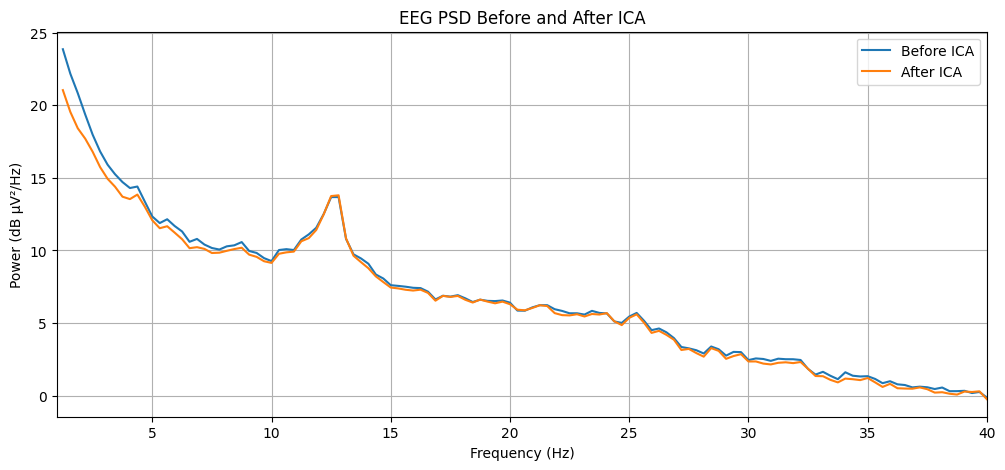

In [37]:
import numpy as np
import matplotlib.pyplot as plt

# 计算清理前的 PSD
psd_before = raw_montage.compute_psd(
    method="welch",
    fmin=1,
    fmax=40,
    picks="eeg",
    n_fft=512,
    n_per_seg=512,
    n_overlap=256,
    verbose=False
)

# 计算清理后的 PSD
psd_after = raw_clean_test.compute_psd(
    method="welch",
    fmin=1,
    fmax=40,
    picks="eeg",
    n_fft=512,
    n_per_seg=512,
    n_overlap=256,
    verbose=False
)

# 获取 PSD 数据和频率
power_before, freqs = psd_before.get_data(return_freqs=True)
power_after = psd_after.get_data()

# 转换为 µV²/Hz
power_before = power_before * 1e12
power_after = power_after * 1e12

# 对64个通道取平均
mean_before = np.mean(power_before, axis=0)
mean_after = np.mean(power_after, axis=0)

# 绘制对比图
plt.figure(figsize=(12, 5))

plt.plot(
    freqs,
    10 * np.log10(mean_before),
    label="Before ICA"
)

plt.plot(
    freqs,
    10 * np.log10(mean_after),
    label="After ICA"
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB µV²/Hz)")
plt.title("EEG PSD Before and After ICA")
plt.legend()
plt.grid(True)
plt.xlim(1, 40)

plt.show()

In [38]:
import numpy as np
import pandas as pd

regions = {
    "额前区": ["Fp1", "Fp2", "Fpz", "AF3", "AF7", "AF8"],
    "中央区": ["C3", "Cz", "C4"],
    "枕区": ["O1", "Oz", "O2"]
}

bands = {
    "Delta": (1, 4),
    "Theta": (4, 8),
    "Alpha": (8, 13),
    "Beta": (13, 30),
    "Gamma": (30, 40)
}

# 频率索引
rows = []

for region, channels in regions.items():

    for band, (fmin, fmax) in bands.items():

        # 找到当前频段的频率点
        mask = (freqs >= fmin) & (freqs <= fmax)

        # 找到对应通道
        indices = [
            psd_before.ch_names.index(ch)
            for ch in channels
        ]

        # 对脑区内通道取平均，再对频率积分
        before = np.mean(power_before[indices], axis=0)
        after = np.mean(power_after[indices], axis=0)

        before_power = np.trapezoid(
            before[mask], freqs[mask]
        )

        after_power = np.trapezoid(
            after[mask], freqs[mask]
        )

        change = (
            (after_power - before_power)
            / before_power * 100
        )

        rows.append({
            "脑区": region,
            "频段": band,
            "清理前功率": before_power,
            "清理后功率": after_power,
            "变化百分比": change
        })

regional_psd_report = pd.DataFrame(rows)

display(regional_psd_report.round(2))

,脑区,频段,清理前功率,清理后功率,变化百分比
0,额前区,Delta,767.87,174.30,-77.30
1,额前区,Theta,97.88,49.51,-49.42
2,额前区,Alpha,59.23,42.61,-28.06
3,额前区,Beta,80.73,61.51,-23.81
4,额前区,Gamma,26.82,20.76,-22.60
5,中央区,Delta,86.03,73.25,-14.85
6,中央区,Theta,37.53,35.51,-5.38
7,中央区,Alpha,42.22,40.98,-2.96
8,中央区,Beta,42.54,41.36,-2.78
9,中央区,Gamma,9.50,9.05,-4.76


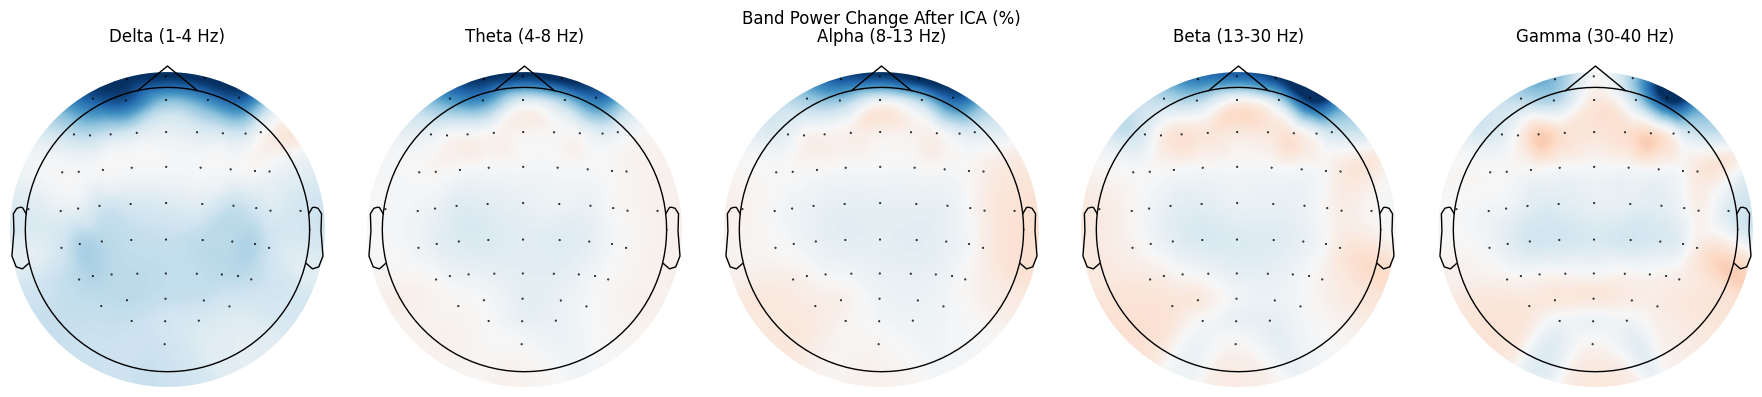

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import mne

bands = {
    "Delta (1-4 Hz)": (1, 4),
    "Theta (4-8 Hz)": (4, 8),
    "Alpha (8-13 Hz)": (8, 13),
    "Beta (13-30 Hz)": (13, 30),
    "Gamma (30-40 Hz)": (30, 40)
}

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, (band, (fmin, fmax)) in zip(axes, bands.items()):

    mask = (freqs >= fmin) & (freqs <= fmax)

    before = np.trapezoid(
        power_before[:, mask],
        freqs[mask],
        axis=1
    )

    after = np.trapezoid(
        power_after[:, mask],
        freqs[mask],
        axis=1
    )

    change = (
        (after - before) /
        (before + 1e-20) * 100
    )

    mne.viz.plot_topomap(
        change,
        raw_montage.info,
        axes=ax,
        show=False,
        cmap="RdBu_r",
        contours=0
    )

    ax.set_title(band)

plt.suptitle("Band Power Change After ICA (%)")
plt.tight_layout()
plt.show()

In [40]:
# 汇总每个电极的频段功率变化
channel_changes = pd.DataFrame({
    "Channel": psd_before.ch_names
})

for band, (fmin, fmax) in bands.items():

    mask = (freqs >= fmin) & (freqs <= fmax)

    before = np.trapezoid(
        power_before[:, mask],
        freqs[mask],
        axis=1
    )

    after = np.trapezoid(
        power_after[:, mask],
        freqs[mask],
        axis=1
    )

    change = (after - before) / (before + 1e-20) * 100

    channel_changes[band] = change

# 查看每个频段下降最多和增加最多的5个电极
for band in bands:

    print(f"\n===== {band} =====")

    print("下降最多的5个电极：")
    display(
        channel_changes.nsmallest(5, band)[
            ["Channel", band]
        ].round(2)
    )

    print("增加最多的5个电极：")
    display(
        channel_changes.nlargest(5, band)[
            ["Channel", band]
        ].round(2)
    )


===== Delta (1-4 Hz) =====
下降最多的5个电极：


,Channel,Delta (1-4 Hz)
23,Fp2,-84.73
21,Fp1,-84.03
22,Fpz,-81.02
28,AF8,-70.51
24,AF7,-70.03


增加最多的5个电极：


,Channel,Delta (1-4 Hz)
38,FT7,-0.18
1,FC3,-0.33
6,FC6,-0.58
2,FC1,-0.88
0,FC5,-0.89



===== Theta (4-8 Hz) =====
下降最多的5个电极：


,Channel,Theta (4-8 Hz)
23,Fp2,-61.88
21,Fp1,-59.12
22,Fpz,-56.26
28,AF8,-45.19
24,AF7,-35.94


... (10 outputs left out)


===== Gamma (30-40 Hz) =====
下降最多的5个电极：


,Channel,Gamma (30-40 Hz)
28,AF8,-50.30
21,Fp1,-21.47
23,Fp2,-18.05
25,AF3,-13.52
24,AF7,-13.31


增加最多的5个电极：


,Channel,Gamma (30-40 Hz)
31,F3,12.91
35,F4,11.08
34,F2,7.94
32,F1,7.46
33,Fz,6.13


In [41]:
import numpy as np
import pandas as pd
import mne

# 选择出现明显 Gamma 增加的额前电极
channels = ["Fp1", "Fp2", "Fpz", "AF4"]

# 分别获取清理前和清理后的数据
data_before = raw_montage.get_data(picks=channels)
data_after = raw_clean.get_data(picks=channels)

sfreq = raw_montage.info["sfreq"]

# 计算 30–40 Hz 功率谱密度
psd_before, freqs = mne.time_frequency.psd_array_welch(
    data_before,
    sfreq=sfreq,
    fmin=30,
    fmax=40,
    n_fft=512,
    verbose=False
)

psd_after, freqs = mne.time_frequency.psd_array_welch(
    data_after,
    sfreq=sfreq,
    fmin=30,
    fmax=40,
    n_fft=512,
    verbose=False
)

# 计算频段平均 PSD
gamma_before = np.mean(psd_before, axis=1)
gamma_after = np.mean(psd_after, axis=1)

result = pd.DataFrame({
    "Channel": channels,
    "清理前Gamma平均PSD": gamma_before,
    "清理后Gamma平均PSD": gamma_after,
    "变化百分比": (
        (gamma_after - gamma_before)
        / gamma_before * 100
    )
})

display(result.round(4))

NameError: name 'raw_clean' is not defined

In [ ]:
# 将 PSD 从 V²/Hz 转换为 µV²/Hz
# 1 V² = 10^12 µV²

gamma_before_uv = gamma_before * 1e12
gamma_after_uv = gamma_after * 1e12

result = pd.DataFrame({
    "Channel": channels,
    "清理前Gamma PSD(µV²/Hz)": gamma_before_uv,
    "清理后Gamma PSD(µV²/Hz)": gamma_after_uv,
    "变化百分比": (
        (gamma_after_uv - gamma_before_uv)
        / gamma_before_uv * 100
    )
})

display(result.round(4))

In [ ]:
# 检查清理前后的信号差异
difference = data_before - data_after

check_result = pd.DataFrame({
    "Channel": channels,
    "清理前标准差(µV)": np.std(data_before, axis=1) * 1e6,
    "清理后标准差(µV)": np.std(data_after, axis=1) * 1e6,
    "最大绝对差异(µV)": np.max(np.abs(difference), axis=1) * 1e6,
    "平均绝对差异(µV)": np.mean(np.abs(difference), axis=1) * 1e6
})

display(check_result.round(6))

print("清理前后数据是否完全相同：",
      np.array_equal(data_before, data_after))

In [ ]:
# 复制原始数据和 ICA 模型，避免修改原对象
raw_clean_check = raw_montage.copy()
ica_check = ica.copy()

# 明确指定排除 ICA000
ica_check.exclude = [0]

# 执行 ICA 清理
ica_check.apply(raw_clean_check)

# 比较 Fp1、Fp2、Fpz、AF4
channels = ["Fp1", "Fp2", "Fpz", "AF4"]

before_check = raw_montage.get_data(picks=channels)
after_check = raw_clean_check.get_data(picks=channels)

diff_check = before_check - after_check

check_result = pd.DataFrame({
    "Channel": channels,
    "最大绝对差异(µV)": np.max(
        np.abs(diff_check), axis=1
    ) * 1e6,
    "平均绝对差异(µV)": np.mean(
        np.abs(diff_check), axis=1
    ) * 1e6
})

display(check_result.round(6))

print("本次排除成分：", ica_check.exclude)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 清理前 PSD
psd_before_check = raw_montage.compute_psd(
    method="welch",
    fmin=1,
    fmax=40,
    picks="eeg",
    n_fft=512,
    n_per_seg=512,
    n_overlap=256,
    verbose=False
)

# 清理后 PSD
psd_after_check = raw_clean_check.compute_psd(
    method="welch",
    fmin=1,
    fmax=40,
    picks="eeg",
    n_fft=512,
    n_per_seg=512,
    n_overlap=256,
    verbose=False
)

power_before_check, freqs = psd_before_check.get_data(
    return_freqs=True
)

power_after_check = psd_after_check.get_data()

# 转换单位
power_before_check *= 1e12
power_after_check *= 1e12

# 全通道平均
mean_before_check = np.mean(power_before_check, axis=0)
mean_after_check = np.mean(power_after_check, axis=0)

plt.figure(figsize=(12, 5))

plt.plot(
    freqs,
    10 * np.log10(mean_before_check),
    label="Before ICA"
)

plt.plot(
    freqs,
    10 * np.log10(mean_after_check),
    label="After ICA000 removal"
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB µV²/Hz)")
plt.title("Corrected EEG PSD Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# 查找当前 Notebook 中所有 Raw 数据对象
for name, obj in globals().copy().items():
    if isinstance(obj, mne.io.BaseRaw):
        print(
            f"变量名：{name} | "
            f"时长：{obj.times[-1]:.3f}s | "
            f"通道数：{len(obj.ch_names)}"
        )

In [ ]:
import os

# 创建保存目录
os.makedirs("results/ICA_model", exist_ok=True)

# 保存 ICA 清理后的 EEG 数据
cleaned_path = "results/ICA_model/EEG_ICA_cleaned_raw.fif"

raw_clean_check.save(
    cleaned_path,
    overwrite=True,
    verbose=False
)

print("保存成功：", cleaned_path)
print("数据时长：", round(raw_clean_check.times[-1], 3), "秒")
print("通道数量：", len(raw_clean_check.ch_names))
print("排除的 ICA 成分：", [0])

In [ ]:
# 重新读取刚刚保存的 ICA 清理数据
raw_final = mne.io.read_raw_fif(
    "results/ICA_model/EEG_ICA_cleaned_raw.fif",
    preload=True,
    verbose=False
)

print("===== 最终数据验证 =====")
print("通道数量：", len(raw_final.ch_names))
print("数据时长：", round(raw_final.times[-1], 3), "秒")
print("采样率：", raw_final.info["sfreq"], "Hz")
print("数据形状：", raw_final.get_data().shape)
print("NaN 数量：", np.isnan(raw_final.get_data()).sum())
print("Inf 数量：", np.isinf(raw_final.get_data()).sum())

In [ ]:
import json
import os

ica_record = {
    "project": "EEG Quality Control and ICA",
    "sampling_rate_hz": 160.0,
    "eeg_channels": 64,
    "ica_method": "FastICA",
    "ica_components": 28,
    "excluded_components": [0],
    "component_name": "ICA000",
    "suspected_artifact": "Ocular-related artifact",
    "evidence": [
        "Frontal-dominant spatial distribution",
        "Strong low-frequency power",
        "Large transient activity around 102.7-103.5 seconds",
        "Removal reduced the frontal transient amplitude"
    ],
    "eog_channel_available": False,
    "interpretation": (
        "ICA000 is highly suspected to be ocular-related, "
        "but cannot be conclusively identified without an independent "
        "EOG channel or video evidence."
    ),
    "cleaned_data": "EEG_ICA_cleaned_raw.fif"
}

record_path = "results/ICA_model/ICA_decision_record.json"

with open(record_path, "w", encoding="utf-8") as f:
    json.dump(ica_record, f, ensure_ascii=False, indent=4)

print("ICA 判断记录已保存：", record_path)

In [ ]:
raw_ref.save("results/EEG_referenced_raw.fif", overwrite=True, verbose=False)
print("已保存：results/EEG_referenced_raw.fif")

In [ ]:
import os

for root, dirs, files in os.walk("results"):
    level = root.replace("results", "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

In [ ]:
import mne
import numpy as np

# 读取两个文件
raw_a = mne.io.read_raw_fif(
    "results/ICA_model/EEG_ICA000_removed_raw.fif",
    preload=True,
    verbose=False
)

raw_b = mne.io.read_raw_fif(
    "results/ICA_model/EEG_ICA_cleaned_raw.fif",
    preload=True,
    verbose=False
)

# 比较数据
data_a = raw_a.get_data()
data_b = raw_b.get_data()

print("文件A形状：", data_a.shape)
print("文件B形状：", data_b.shape)

print(
    "最大绝对差异：",
    np.max(np.abs(data_a - data_b))
)

print(
    "平均绝对差异：",
    np.mean(np.abs(data_a - data_b))
)

In [ ]:
# 确认清理前后数据中的通道名称

target_channels = ["Fp1", "Fp2", "Fpz"]

print("===== 清理前数据 =====")
for ch in target_channels:
    print(ch, "是否存在：", ch in raw_montage.ch_names)

print("\n===== 清理后数据 =====")
for ch in target_channels:
    print(ch, "是否存在：", ch in raw_final.ch_names)

print("\n清理前通道名称：")
print(raw_montage.ch_names[:15])

In [ ]:
import numpy as np

# 设置需要比较的通道
target_channels = ["Fp1", "Fp2", "Fpz"]

# 设置分析时间范围
start_time = 100
end_time = 106

# 提取清理前后的数据
before_data = raw_montage.get_data(
    picks=target_channels,
    start=start_time * 160,
    stop=end_time * 160
) * 1e6

after_data = raw_final.get_data(
    picks=target_channels,
    start=start_time * 160,
    stop=end_time * 160
) * 1e6

# 创建时间轴
times = np.arange(
    start_time * 160,
    end_time * 160
) / 160

print("清理前数据形状：", before_data.shape)
print("清理后数据形状：", after_data.shape)
print("时间轴长度：", len(times))
print("单位：µV")

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 10),
    sharex=True
)

for i, ch in enumerate(target_channels):

    # 清理前
    axes[i].plot(
        times,
        before_data[i],
        label="Before ICA",
        linewidth=0.9,
        alpha=0.8
    )

    # 清理后
    axes[i].plot(
        times,
        after_data[i],
        label="After ICA000 removal",
        linewidth=0.9,
        alpha=0.8
    )

    # 标记异常事件区间
    axes[i].axvspan(
        102.7, 103.5,
        color="red",
        alpha=0.15,
        label="Suspected artifact"
    )

    axes[i].set_ylabel("Amplitude (µV)")
    axes[i].set_title(f"{ch} - ICA Artifact Removal")
    axes[i].legend(loc="upper right")
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")

fig.suptitle(
    "EEG Signal Before and After ICA000 Removal",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
import os
import matplotlib.pyplot as plt

# 创建图表目录
os.makedirs("figures/ICA", exist_ok=True)

# 保存高清 PNG
fig.savefig(
    "figures/ICA/ICA000_before_after_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

# 保存 PDF
fig.savefig(
    "figures/ICA/ICA000_before_after_comparison.pdf",
    bbox_inches="tight"
)

print("图表保存成功！")
print("PNG：figures/ICA/ICA000_before_after_comparison.png")
print("PDF：figures/ICA/ICA000_before_after_comparison.pdf")

In [ ]:
import os

files_to_check = [
    "figures/ICA/ICA000_before_after_comparison.png",
    "figures/ICA/ICA000_before_after_comparison.pdf"
]

for path in files_to_check:
    if os.path.exists(path):
        print(f"已保存：{path}")
        print(f"文件大小：{os.path.getsize(path) / 1024:.2f} KB")
    else:
        print(f"尚未找到：{path}")

In [ ]:
import os

os.makedirs("reports", exist_ok=True)

report = """# Project 03: EEG Artifact Identification and ICA Cleaning

## 1. Project Overview

本项目使用 MNE-Python 对 EEG 数据进行质量控制、
独立成分分析（ICA）以及疑似眼动伪迹识别与清理。

项目目标：
- 检查 EEG 数据质量
- 建立标准电极位置信息
- 使用 ICA 分离独立成分
- 识别疑似眼动相关伪迹
- 验证清理前后的信号变化
- 保存可复现的处理结果

## 2. Dataset Information

- EEG channels: 64
- Sampling rate: 160 Hz
- Number of samples: 20,000
- Duration: 124.994 seconds
- NaN values: 0
- Inf values: 0

## 3. Preprocessing

- EEG average reference
- Standard 10-05 montage assignment
- ICA decomposition using FastICA
- Number of ICA components: 28

## 4. ICA Component Assessment

ICA component 000 was selected for further assessment.

Observed evidence:
- Frontal-dominant spatial distribution
- Strong low-frequency activity
- Large transient activity around 102.7–103.5 seconds
- Similar abnormal activity across frontal electrodes
- Reduced frontal transient amplitude after component removal

The component was considered highly suspected to be ocular-related.

Important limitation:
No independent EOG channel or video recording was available.
Therefore, the ocular origin cannot be conclusively confirmed.

## 5. ICA Cleaning

ICA component 000 was excluded in a copy of the original
referenced and montage-corrected EEG data.

The cleaned dataset was saved as:

results/ICA_model/EEG_ICA_cleaned_raw.fif

## 6. Before-and-After Comparison

The following frontal channels were compared:

- Fp1
- Fp2
- Fpz

Analysis interval:
100–106 seconds

Suspected artifact interval:
102.7–103.5 seconds

The large transient activity was visibly reduced after
ICA component 000 removal.

Figure files:

- figures/ICA/ICA000_before_after_comparison.png
- figures/ICA/ICA000_before_after_comparison.pdf

## 7. Data Validation

The saved cleaned dataset was reloaded successfully.

- Channels: 64
- Sampling rate: 160 Hz
- Data shape: (64, 20000)
- NaN count: 0
- Inf count: 0

## 8. Limitations

- No independent EOG channel was available.
- The ocular origin of ICA000 remains a well-supported
  hypothesis rather than a confirmed diagnosis.
- Only ICA000 was excluded.
- The overall PSD changed only slightly; this does not
  establish that all artifacts were removed.
- Further validation using EOG, video, and additional
  physiological data is recommended.

## 9. Conclusion

This project demonstrates an EEG quality-control and ICA
artifact-assessment workflow using MNE-Python.

The results show that ICA component 000 removal substantially
reduced a large transient in frontal EEG channels.

The cleaned data and analysis records were saved for
reproducibility and further analysis.
"""

report_path = "reports/ICA_Analysis_Report.md"

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

print("报告创建成功：", report_path)
print("文件大小：", os.path.getsize(report_path), "bytes")

In [ ]:
# 检查报告是否包含关键章节

with open(
    "reports/ICA_Analysis_Report.md",
    "r",
    encoding="utf-8"
) as f:
    report_text = f.read()

required_sections = [
    "Project Overview",
    "Dataset Information",
    "Preprocessing",
    "ICA Component Assessment",
    "ICA Cleaning",
    "Before-and-After Comparison",
    "Data Validation",
    "Limitations",
    "Conclusion"
]

print("===== 报告完整性检查 =====")

for section in required_sections:
    status = "通过" if section in report_text else "缺失"
    print(f"{section}: {status}")

print("\n报告总字符数：", len(report_text))

In [ ]:
readme = """# Project 03: EEG Quality Control and ICA Artifact Removal

## Overview

This project demonstrates EEG quality control and Independent
Component Analysis (ICA) using MNE-Python.

## Objectives

- Perform EEG data quality assessment
- Assign standard electrode locations
- Apply FastICA decomposition
- Assess suspected ocular-related artifacts
- Compare EEG signals before and after ICA cleaning
- Validate and save the cleaned EEG dataset

## Dataset

- EEG channels: 64
- Sampling rate: 160 Hz
- Duration: 124.994 seconds
- ICA components: 28

## Key Result

ICA component 000 was identified as highly suspected
to be ocular-related based on its frontal-dominant
topography, low-frequency activity, and transient
activity around 102.7–103.5 seconds.

After removing this component, the large transient
was visibly reduced in Fp1, Fp2, and Fpz.

The ocular origin was not conclusively confirmed
because no independent EOG channel or video was available.

## Project Structure

- notebooks/: Jupyter Notebook
- reports/: Analysis report
- figures/: Before-and-after comparison figures
- results/: ICA model and cleaned EEG data

## Tools

- Python
- MNE-Python
- NumPy
- Pandas
- Matplotlib

## Reproducibility

The analysis report, ICA parameters, decision record,
and cleaned dataset are provided as project outputs.

## Limitations

Only ICA component 000 was excluded.
Further validation with independent EOG or video data
is recommended.
"""

with open(
    "README_Project03.md",
    "w",
    encoding="utf-8"
) as f:
    f.write(readme)

print("README 创建成功：README_Project03.md")

In [ ]:
import os
import shutil

# 创建项目03的统一目录
portfolio_dir = "EEG-Analysis-Portfolio"
project_dir = os.path.join(
    portfolio_dir,
    "Project_03_ICA_Artifact_Removal"
)

folders = [
    "notebooks",
    "reports",
    "figures/ICA",
    "results"
]

for folder in folders:
    os.makedirs(
        os.path.join(project_dir, folder),
        exist_ok=True
    )

# 复制报告
shutil.copy2(
    "reports/ICA_Analysis_Report.md",
    os.path.join(project_dir, "reports/ICA_Analysis_Report.md")
)

# 复制 README
shutil.copy2(
    "README_Project03.md",
    os.path.join(project_dir, "README.md")
)

# 复制对比图
for ext in ["png", "pdf"]:
    src = f"figures/ICA/ICA000_before_after_comparison.{ext}"
    dst = os.path.join(
        project_dir,
        f"figures/ICA/ICA000_before_after_comparison.{ext}"
    )
    shutil.copy2(src, dst)

print("项目03目录创建成功：", project_dir)

In [ ]:
import os
import shutil

source_dir = "results/ICA_model"
target_dir = "EEG-Analysis-Portfolio/Project_03_ICA_Artifact_Removal/results"

files = [
    "EEG_ICA_model.fif",
    "EEG_ICA_cleaned_raw.fif",
    "ICA_parameters.json",
    "ICA_decision_record.json"
]

for filename in files:
    source = os.path.join(source_dir, filename)
    target = os.path.join(target_dir, filename)

    shutil.copy2(source, target)

    print(
        "复制成功：",
        filename,
        "|",
        round(os.path.getsize(target) / 1024, 2),
        "KB"
    )

print("\n项目03核心结果复制完成！")

In [ ]:
import os

print("当前工作目录：", os.getcwd())
print("\n当前目录中的 Notebook 文件：")

for file in os.listdir("."):
    if file.endswith(".ipynb"):
        print(file)

In [ ]:
import os
import shutil

source = "03_EEG_QualityControl_ICA.ipynb"

target = (
    "EEG-Analysis-Portfolio/"
    "Project_03_ICA_Artifact_Removal/"
    "notebooks/"
    "03_EEG_QualityControl_ICA.ipynb"
)

shutil.copy2(source, target)

print("Notebook 复制成功！")
print("目标位置：", target)
print("文件大小：", round(os.path.getsize(target) / 1024, 2), "KB")

In [ ]:
import os

project_dir = (
    "EEG-Analysis-Portfolio/"
    "Project_03_ICA_Artifact_Removal"
)

print("===== Project 03 文件清单 =====")

for root, dirs, files in os.walk(project_dir):
    level = root.replace(project_dir, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for filename in files:
        path = os.path.join(root, filename)
        size_mb = os.path.getsize(path) / (1024 * 1024)

        print(f"{indent}    {filename} ({size_mb:.2f} MB)")

In [ ]:
import nbformat

notebook_path = (
    "EEG-Analysis-Portfolio/"
    "Project_03_ICA_Artifact_Removal/"
    "notebooks/"
    "03_EEG_QualityControl_ICA.ipynb"
)

nb = nbformat.read(notebook_path, as_version=4)

code_cells = [
    cell for cell in nb.cells
    if cell.cell_type == "code"
]

output_count = sum(
    len(cell.get("outputs", []))
    for cell in code_cells
)

print("代码单元格数量：", len(code_cells))
print("输出总数量：", output_count)

print("\n各代码单元格输出数量：")
for i, cell in enumerate(code_cells):
    print(f"代码单元格 {i + 1}：{len(cell.get('outputs', []))} 个输出")

In [ ]:
import nbformat
import json

notebook_path = (
    "EEG-Analysis-Portfolio/"
    "Project_03_ICA_Artifact_Removal/"
    "notebooks/"
    "03_EEG_QualityControl_ICA.ipynb"
)

nb = nbformat.read(notebook_path, as_version=4)

print("===== 输出占用空间检查 =====")

for i, cell in enumerate(nb.cells):

    if cell.cell_type != "code":
        continue

    total_size = 0
    output_types = []

    for output in cell.get("outputs", []):

        output_types.append(output.output_type)

        data = output.get("data", {})

        for mime, content in data.items():
            total_size += len(
                json.dumps(content, ensure_ascii=False).encode("utf-8")
            )

        if output.output_type == "stream":
            total_size += len(output.get("text", "").encode("utf-8"))

    if total_size > 10000 or i == 40:
        print(
            f"单元格 {i + 1} | "
            f"输出数量：{len(cell.outputs)} | "
            f"类型：{output_types} | "
            f"数据大小：{total_size / 1024:.1f} KB"
        )

In [ ]:
import nbformat
import json

notebook_path = (
    "EEG-Analysis-Portfolio/"
    "Project_03_ICA_Artifact_Removal/"
    "notebooks/"
    "03_EEG_QualityControl_ICA.ipynb"
)

nb = nbformat.read(notebook_path, as_version=4)

target_cells = [13, 17, 26, 29, 34, 35]

for cell_number in target_cells:

    # 找到对应的代码单元格（按代码单元格编号）
    code_cells = [
        cell for cell in nb.cells
        if cell.cell_type == "code"
    ]

    cell = code_cells[cell_number - 1]

    print("\n" + "=" * 50)
    print("代码单元格：", cell_number)

    print("\n代码内容：")
    print(cell.source[:500])

    print("\n输出类型和大小：")

    for output in cell.outputs:
        if "data" in output:
            for mime, content in output.data.items():
                size = len(
                    json.dumps(
                        content,
                        ensure_ascii=False
                    ).encode("utf-8")
                )
                print(mime, round(size / 1024, 1), "KB")

In [ ]:
import nbformat

notebook_path = (
    "EEG-Analysis-Portfolio/"
    "Project_03_ICA_Artifact_Removal/"
    "notebooks/"
    "03_EEG_QualityControl_ICA.ipynb"
)

nb = nbformat.read(notebook_path, as_version=4)

code_cells = [
    cell for cell in nb.cells
    if cell.cell_type == "code"
]

for number in [34, 35]:

    cell = code_cells[number - 1]

    print("\n" + "=" * 60)
    print(f"第 {number} 个代码单元格完整内容：")
    print("=" * 60)

    print(cell.source)